# SignSense: Deep CNN-Based Traffic Sign Recognition

**Deep Learning mini project** - Shayaan Shaikh, Yash Rane, Dishant Sasane

This notebook runs the whole project end to end on the GTSRB dataset (43 classes):
data exploration, a custom CNN (Model A), MobileNetV2 transfer learning (Model B),
evaluation, comparison and predictions.

**How to run:** `Runtime -> Change runtime type -> T4 GPU`, then `Runtime -> Run all`.
Cell 3.1 asks for your Kaggle username and key (from `kaggle.json`).
The full run takes roughly 30-40 minutes on a free T4 GPU.

## 1. Setup

In [1]:
# Check the GPU and create the project folders
!nvidia-smi -L
import tensorflow as tf
print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))
!mkdir -p /content/signsense/src /content/signsense/scripts /content/signsense/data
%cd /content/signsense

GPU 0: Tesla T4 (UUID: GPU-e217c0cf-0707-7e2e-68ac-17ab2a6162d7)
TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
/content/signsense


## 2. Project code

Each cell below writes one module of the project. The same files are in the
`src/` folder of the repository. `config.py` holds every path and hyperparameter.

In [2]:
%%writefile src/__init__.py
"""SignSense: traffic sign recognition with CNNs."""


Writing src/__init__.py


In [3]:
%%writefile src/config.py
"""
Central configuration for SignSense.

All paths and hyperparameters live here, so the rest of the code
has no "magic numbers" and no hardcoded absolute paths.
"""

from pathlib import Path

# ---------------------------------------------------------------
# Paths (all relative to the project root, so the code runs anywhere)
# ---------------------------------------------------------------
BASE_DIR = Path(__file__).resolve().parent.parent   # project root folder
DATA_DIR = BASE_DIR / "data"
TRAIN_DIR = DATA_DIR / "Train"                      # Train/<class_id>/*.png
TEST_DIR = DATA_DIR / "Test"                        # Test/*.png
TEST_CSV = DATA_DIR / "Test.csv"                    # labels for test images
META_DIR = DATA_DIR / "Meta"                        # reference image of each sign
SIGNNAMES_CSV = DATA_DIR / "signnames.csv"          # ClassId -> SignName
MODELS_DIR = BASE_DIR / "models"                    # saved .keras models
RESULTS_DIR = BASE_DIR / "results"                  # plots, tables, reports

# Saved model files
CUSTOM_CNN_PATH = MODELS_DIR / "custom_cnn.keras"         # baseline from the brief (98.05%)
CUSTOM_CNN_BN_PATH = MODELS_DIR / "custom_cnn_bn.keras"   # + BatchNorm (98.60%)
MOBILENET_PATH = MODELS_DIR / "mobilenetv2.keras"

# Models used in the demo app and the final comparison
MODEL_A_NAME = "custom_cnn_bn"   # Model A: custom CNN + BatchNorm (best, 98.60%)
MODEL_B_NAME = "mobilenetv2"     # Model B: MobileNetV2 transfer learning (88.30%)
MODEL_A_PATH = CUSTOM_CNN_BN_PATH

# ---------------------------------------------------------------
# Dataset
# ---------------------------------------------------------------
NUM_CLASSES = 43            # GTSRB has 43 sign classes (0 to 42)
KAGGLE_DATASET = "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"

# ---------------------------------------------------------------
# Image sizes
# ---------------------------------------------------------------
IMG_SIZE = 32               # custom CNN input: 32x32 pixels
MOBILENET_IMG_SIZE = 96     # MobileNetV2 needs larger images
NUM_CHANNELS = 3            # RGB colour images

# ---------------------------------------------------------------
# Training hyperparameters
# ---------------------------------------------------------------
BATCH_SIZE = 64             # images per training step
EPOCHS = 20                 # max epochs for the custom CNN
MOBILENET_EPOCHS = 10       # epochs for training the MobileNetV2 head
# Fine-tuning settings. Run 1 used 20 layers / 1e-5 / 5 epochs and reached only
# 66.75% test accuracy, so run 2 fine-tunes more layers, faster and for longer.
FINE_TUNE_EPOCHS = 15       # extra epochs when fine-tuning MobileNetV2
FINE_TUNE_LAYERS = 60       # how many top MobileNetV2 layers to unfreeze (of ~154)
LEARNING_RATE = 1e-3        # Adam learning rate
FINE_TUNE_LR = 1e-4         # smaller learning rate for fine-tuning
VAL_SPLIT = 0.2             # 20% of training data used for validation
RANDOM_SEED = 42            # fixed seed for reproducible results
SHUFFLE_BUFFER = 5000       # images kept in the tf.data shuffle buffer (MobileNetV2)

# Callbacks
EARLY_STOP_PATIENCE = 5     # stop if val_loss does not improve for 5 epochs
REDUCE_LR_PATIENCE = 3      # halve the learning rate after 3 flat epochs
REDUCE_LR_FACTOR = 0.5

# ---------------------------------------------------------------
# Data augmentation (NO flips: flipping changes a sign's meaning,
# e.g. "turn left" would become "turn right")
# ---------------------------------------------------------------
ROTATION_RANGE = 10         # degrees
ZOOM_RANGE = 0.15
WIDTH_SHIFT_RANGE = 0.1
HEIGHT_SHIFT_RANGE = 0.1
SHEAR_RANGE = 0.1

# ---------------------------------------------------------------
# Prediction / demo app
# ---------------------------------------------------------------
LOW_CONFIDENCE = 0.5        # below 50% the app shows a "not sure" warning
TOP_K = 3                   # number of top predictions to display


Writing src/config.py


In [4]:
%%writefile src/data_loader.py
"""
Load GTSRB images and labels from disk.

Main functions:
    load_train_data()  -> X, y from data/Train/<class_id>/*.png
    load_test_data()   -> X, y from data/Test + Test.csv
    load_sign_names()  -> {class_id: "sign name"}

Loading ~52,000 images takes a minute, so the result is cached in a
.npz file inside data/. The next load reads the cache in a few seconds.
"""

import random
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from src import config


def set_seeds(seed=config.RANDOM_SEED):
    """Fix random seeds so results are the same every run."""
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


def load_sign_names():
    """Return a dictionary mapping class id (int) to sign name (str)."""
    names_df = pd.read_csv(config.SIGNNAMES_CSV)
    return dict(zip(names_df["ClassId"], names_df["SignName"]))


def load_image(image_path, img_size=config.IMG_SIZE):
    """Read one image, convert BGR -> RGB, and resize to img_size x img_size."""
    image = cv2.imread(str(image_path))
    if image is None:
        raise ValueError(f"Could not read image: {image_path}")
    # OpenCV loads colours as BGR; the rest of our code (and Matplotlib) expects RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(image, (img_size, img_size), interpolation=cv2.INTER_AREA)
    return image


def find_image_folder(folder):
    """
    Return the folder that actually contains the .png images.

    The Kaggle zip has both "Train" and "train" (and "Test" and "test").
    Windows treats them as one folder, but on Linux (Colab) they are two
    different folders and the images may be in the lowercase one.
    """
    lowercase_folder = folder.parent / folder.name.lower()
    for candidate in [folder, lowercase_folder]:
        if candidate.exists() and any(candidate.rglob("*.png")):
            return candidate
    raise FileNotFoundError(f"No .png images found in {folder} or {lowercase_folder}. "
                            "Run scripts/download_data.py first.")


def _read_train_folders(img_size):
    """Read every image in Train/<class_id>/ and return (X, y) arrays."""
    train_dir = find_image_folder(config.TRAIN_DIR)
    images = []
    labels = []
    # Sort numerically: 0, 1, 2, ... 42 (alphabetical would give 0, 1, 10, 11, ...)
    for class_id in range(config.NUM_CLASSES):
        class_folder = train_dir / str(class_id)
        for image_path in sorted(class_folder.glob("*.png")):
            images.append(load_image(image_path, img_size))
            labels.append(class_id)
        print(f"  class {class_id:2d}: done", end="\r")
    print()
    return np.array(images, dtype=np.uint8), np.array(labels, dtype=np.int64)


def _read_test_csv(img_size):
    """Read every test image listed in Test.csv and return (X, y) arrays."""
    test_df = pd.read_csv(config.TEST_CSV)
    test_dir = find_image_folder(config.TEST_DIR)
    images = []
    # Paths in Test.csv look like "Test/00000.png"; we only need the file name
    for relative_path in test_df["Path"]:
        images.append(load_image(test_dir / Path(relative_path).name, img_size))
    labels = test_df["ClassId"].to_numpy(dtype=np.int64)
    return np.array(images, dtype=np.uint8), labels


def _load_with_cache(split_name, read_function, img_size):
    """Load (X, y) from a .npz cache if it exists, otherwise read images and save the cache."""
    cache_path = config.DATA_DIR / f"cache_{split_name}_{img_size}.npz"
    if cache_path.exists():
        cached = np.load(cache_path)
        if len(cached["y"]) > 0:   # ignore a broken (empty) cache from a failed run
            print(f"Loading {split_name} data from cache: {cache_path.name}")
            return cached["X"], cached["y"]

    print(f"Reading {split_name} images from disk (first time only)...")
    X, y = read_function(img_size)
    if len(y) == 0:
        raise ValueError(f"No {split_name} images were loaded. Check the data/ folder.")
    np.savez_compressed(cache_path, X=X, y=y)
    return X, y


def load_train_data(img_size=config.IMG_SIZE):
    """Return training images X (N, img_size, img_size, 3) uint8 and labels y (N,)."""
    return _load_with_cache("train", _read_train_folders, img_size)


def load_test_data(img_size=config.IMG_SIZE):
    """Return test images X (N, img_size, img_size, 3) uint8 and labels y (N,)."""
    return _load_with_cache("test", _read_test_csv, img_size)


def plot_sample_images(X, y, sign_names, num_samples=10, save_path=None):
    """Show a grid of random training images with their sign names."""
    random_indices = np.random.choice(len(X), size=num_samples, replace=False)
    fig, axes = plt.subplots(2, num_samples // 2, figsize=(14, 7))

    for ax, index in zip(axes.flat, random_indices):
        ax.imshow(X[index])
        ax.set_title(f"{y[index]}: {sign_names[y[index]]}", fontsize=8, wrap=True)
        ax.axis("off")

    fig.suptitle("Random training samples")
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    return fig


def plot_class_distribution(y, save_path=None):
    """Bar chart of how many training images each class has (shows the imbalance)."""
    counts = np.bincount(y, minlength=config.NUM_CLASSES)
    fig, ax = plt.subplots(figsize=(14, 5))

    ax.bar(range(config.NUM_CLASSES), counts, color="#3b6fb6", width=0.8)
    ax.axhline(counts.mean(), color="#555555", linestyle="--", linewidth=1)
    ax.text(config.NUM_CLASSES - 0.5, counts.mean(), f" mean = {counts.mean():.0f}",
            va="bottom", ha="right", fontsize=9, color="#333333")

    ax.set_title(f"Images per class: {counts.min()} to {counts.max()} (imbalanced)")
    ax.set_xlabel("Class ID")
    ax.set_ylabel("Number of images")
    ax.set_xticks(range(config.NUM_CLASSES))
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="y", color="#e0e0e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    return fig


Writing src/data_loader.py


In [5]:
%%writefile src/preprocess.py
"""
Preprocessing: normalisation, one-hot labels, train/validation split
and data augmentation.

Main function:
    prepare_data() -> X_train, X_val, X_test, y_train, y_val, y_test
"""

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import to_categorical

from src import config
from src.data_loader import load_test_data, load_train_data


def normalize_images(X):
    """Convert pixel values from 0-255 integers to 0-1 floats."""
    return X.astype("float32") / 255.0


def one_hot_labels(y):
    """Turn class ids (e.g. 14) into one-hot vectors of length 43."""
    return to_categorical(y, config.NUM_CLASSES)


def split_train_val(X, y):
    """Split into 80% train / 20% validation, keeping class proportions equal (stratify)."""
    return train_test_split(
        X, y,
        test_size=config.VAL_SPLIT,
        stratify=y,
        random_state=config.RANDOM_SEED,
    )


def prepare_data(img_size=config.IMG_SIZE, normalize=True):
    """
    Load, split and one-hot encode the data (and normalise it for the custom CNN).

    Returns X_train, X_val, X_test (images) and y_train, y_val, y_test (one-hot labels).
    With normalize=False the images stay uint8 (0-255), which MobileNetV2 needs
    and which uses 4x less memory at 96x96.
    """
    X, y = load_train_data(img_size)
    X_test, y_test = load_test_data(img_size)

    # Split BEFORE anything else, so validation images never leak into training
    X_train, X_val, y_train, y_val = split_train_val(X, y)

    if normalize:
        X_train = normalize_images(X_train)
        X_val = normalize_images(X_val)
        X_test = normalize_images(X_test)

    y_train = one_hot_labels(y_train)
    y_val = one_hot_labels(y_val)
    y_test = one_hot_labels(y_test)

    return X_train, X_val, X_test, y_train, y_val, y_test


def create_augmenter():
    """
    Build an ImageDataGenerator that randomly rotates, zooms, shifts and shears images.

    No horizontal/vertical flips: flipping "turn left" would make it look
    like "turn right", which would teach the model wrong labels.
    """
    return ImageDataGenerator(
        rotation_range=config.ROTATION_RANGE,
        zoom_range=config.ZOOM_RANGE,
        width_shift_range=config.WIDTH_SHIFT_RANGE,
        height_shift_range=config.HEIGHT_SHIFT_RANGE,
        shear_range=config.SHEAR_RANGE,
        horizontal_flip=False,
        vertical_flip=False,
        fill_mode="nearest",
    )


def plot_augmented_examples(image, num_versions=8, save_path=None):
    """Show one original image next to several randomly augmented versions of it."""
    augmenter = create_augmenter()
    fig, axes = plt.subplots(1, num_versions + 1, figsize=(2 * (num_versions + 1), 2.4))

    axes[0].imshow(image)
    axes[0].set_title("Original", fontsize=9)

    for ax in axes[1:]:
        # random_transform applies one random augmentation to a single image
        augmented = augmenter.random_transform(image)
        ax.imshow(np.clip(augmented, 0, 1))
        ax.set_title("Augmented", fontsize=9)

    for ax in axes:
        ax.axis("off")
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    return fig


def create_augmentation_layers():
    """
    The same augmentation as create_augmenter(), written as Keras layers so it can
    run inside a tf.data pipeline (used for MobileNetV2). Still no flips.
    """
    return tf.keras.Sequential([
        layers.RandomRotation(config.ROTATION_RANGE / 360),   # factor = fraction of a full turn
        layers.RandomZoom(config.ZOOM_RANGE),
        layers.RandomTranslation(config.HEIGHT_SHIFT_RANGE, config.WIDTH_SHIFT_RANGE),
    ], name="augmentation")


def make_mobilenet_dataset(X, y=None, training=False):
    """
    Build a tf.data pipeline for MobileNetV2 from uint8 images.

    Images are converted to float one batch at a time, so the full 96x96 dataset
    never has to sit in memory as float32. Training batches are shuffled and augmented.
    """
    dataset = tf.data.Dataset.from_tensor_slices(X if y is None else (X, y))
    if training:
        dataset = dataset.shuffle(config.SHUFFLE_BUFFER, seed=config.RANDOM_SEED)
    dataset = dataset.batch(config.BATCH_SIZE)

    augmenter = create_augmentation_layers() if training else None

    def prepare_batch(images, labels=None):
        images = tf.cast(images, tf.float32)
        if augmenter is not None:
            images = augmenter(images, training=True)
        images = preprocess_input(images)   # MobileNetV2 expects pixels scaled to [-1, 1]
        return images if labels is None else (images, labels)

    dataset = dataset.map(prepare_batch, num_parallel_calls=tf.data.AUTOTUNE)
    return dataset.prefetch(tf.data.AUTOTUNE)   # prepare the next batch while the GPU trains


Writing src/preprocess.py


In [6]:
%%writefile src/models.py
"""
Model definitions.

    build_custom_cnn()  -> Model A: a small CNN trained from scratch (32x32 input)
    build_mobilenet()   -> Model B: MobileNetV2 transfer learning (added in Phase 5)
"""

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam

from src import config


def _conv_block(model, filters, use_batchnorm):
    """Add two 3x3 convolutions, then max pooling and dropout."""
    for _ in range(2):
        model.add(layers.Conv2D(filters, (3, 3), activation="relu"))
        if use_batchnorm:
            # BatchNorm keeps activations at a stable scale, which often speeds up training
            model.add(layers.BatchNormalization())
    model.add(layers.MaxPooling2D(pool_size=(2, 2)))   # halve width and height
    model.add(layers.Dropout(0.25))                     # randomly drop 25% to reduce overfitting


def build_custom_cnn(use_batchnorm=False):
    """
    Build and compile the custom CNN (Model A).

    Input (32, 32, 3)
    Conv(32) -> Conv(32) -> MaxPool -> Dropout(0.25)
    Conv(64) -> Conv(64) -> MaxPool -> Dropout(0.25)
    Flatten -> Dense(256) -> Dropout(0.5) -> Dense(43, softmax)
    """
    name = "custom_cnn_bn" if use_batchnorm else "custom_cnn"
    model = models.Sequential(name=name)
    model.add(layers.Input(shape=(config.IMG_SIZE, config.IMG_SIZE, config.NUM_CHANNELS)))

    # Feature extractor: learns edges, shapes, then sign parts
    _conv_block(model, 32, use_batchnorm)
    _conv_block(model, 64, use_batchnorm)

    # Classifier: turns the learned features into 43 class probabilities
    model.add(layers.Flatten())
    model.add(layers.Dense(256, activation="relu"))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(config.NUM_CLASSES, activation="softmax"))

    _compile(model, config.LEARNING_RATE)
    return model


def _compile(model, learning_rate):
    """Compile a model with Adam, categorical cross-entropy and accuracy."""
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="categorical_crossentropy",
        metrics=["accuracy"],
    )


def build_mobilenet():
    """
    Build Model B: MobileNetV2 pre-trained on ImageNet, with a new classifier head.

    Input (96, 96, 3) -> MobileNetV2 base (frozen)
    -> GlobalAveragePooling2D -> Dropout(0.3) -> Dense(43, softmax)

    Returns (model, base_model). base_model is needed later for fine-tuning.
    """
    size = config.MOBILENET_IMG_SIZE
    base_model = MobileNetV2(weights="imagenet", include_top=False,
                             input_shape=(size, size, config.NUM_CHANNELS))
    base_model.trainable = False   # freeze: keep the ImageNet features unchanged at first

    inputs = layers.Input(shape=(size, size, config.NUM_CHANNELS))
    # training=False keeps the base's BatchNorm layers in inference mode,
    # which matters when we unfreeze some layers for fine-tuning later
    features = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(features)   # average each feature map to one number
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(config.NUM_CLASSES, activation="softmax")(x)

    model = models.Model(inputs, outputs, name="mobilenetv2")
    _compile(model, config.LEARNING_RATE)
    return model, base_model


def unfreeze_top_layers(model, base_model, num_layers=config.FINE_TUNE_LAYERS):
    """Unfreeze the last `num_layers` layers of the base and recompile with a small learning rate."""
    base_model.trainable = True
    for layer in base_model.layers[:-num_layers]:
        layer.trainable = False
    # A tiny learning rate nudges the pre-trained weights instead of destroying them
    _compile(model, config.FINE_TUNE_LR)


Writing src/models.py


In [7]:
%%writefile src/train.py
"""
Train a model and save the best version plus its training history.

Run from the project root:
    python -m src.train                          # custom CNN (baseline)
    python -m src.train --batchnorm              # custom CNN + BatchNormalization
    python -m src.train --model mobilenetv2      # MobileNetV2 transfer learning (use a GPU)

Outputs:
    models/<name>.keras             best model (highest validation accuracy)
    results/history_<name>.json     loss/accuracy per epoch + training time
"""

import argparse
import json
import time

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from src import config
from src.data_loader import set_seeds
from src.models import build_custom_cnn, build_mobilenet, unfreeze_top_layers
from src.preprocess import create_augmenter, make_mobilenet_dataset, prepare_data


def get_callbacks(model_path, best_val_accuracy=None):
    """
    Return the callbacks used during training.

    best_val_accuracy: the best score so far (used in fine-tuning, so the saved
    model is only replaced if fine-tuning actually beats the first stage).
    """
    return [
        # Stop when validation loss stops improving, and go back to the best epoch
        EarlyStopping(monitor="val_loss", patience=config.EARLY_STOP_PATIENCE,
                      restore_best_weights=True, verbose=1),
        # Save the model every time validation accuracy reaches a new best
        ModelCheckpoint(str(model_path), monitor="val_accuracy", save_best_only=True,
                        initial_value_threshold=best_val_accuracy, verbose=1),
        # Halve the learning rate when validation loss gets stuck
        ReduceLROnPlateau(monitor="val_loss", factor=config.REDUCE_LR_FACTOR,
                          patience=config.REDUCE_LR_PATIENCE, verbose=1),
    ]


def save_history(history_dict, train_time_sec, save_path):
    """Save per-epoch metrics and total training time to a JSON file."""
    history_dict = {key: [float(v) for v in values] for key, values in history_dict.items()}
    history_dict["train_time_sec"] = round(train_time_sec, 1)
    history_dict["hardware"] = "GPU" if tf.config.list_physical_devices("GPU") else "CPU"
    with open(save_path, "w") as file:
        json.dump(history_dict, file, indent=2)
    print(f"History saved to {save_path}")


def _make_output_folders():
    """Create models/ and results/ if they do not exist yet."""
    config.MODELS_DIR.mkdir(exist_ok=True)
    config.RESULTS_DIR.mkdir(exist_ok=True)


def train_custom_cnn(use_batchnorm=False):
    """Train the custom CNN with data augmentation and save the results."""
    set_seeds()
    _make_output_folders()

    X_train, X_val, _, y_train, y_val, _ = prepare_data()   # test set is NOT used here
    model = build_custom_cnn(use_batchnorm)
    model.summary()

    model_path = config.MODELS_DIR / f"{model.name}.keras"
    # The augmenter creates new randomly rotated/zoomed/shifted batches every epoch
    train_batches = create_augmenter().flow(X_train, y_train,
                                            batch_size=config.BATCH_SIZE, seed=config.RANDOM_SEED)

    start_time = time.time()
    history = model.fit(
        train_batches,
        validation_data=(X_val, y_val),   # validation images are NOT augmented
        epochs=config.EPOCHS,
        callbacks=get_callbacks(model_path),
    )
    train_time = time.time() - start_time
    print(f"Training took {train_time / 60:.1f} minutes. Best model saved to {model_path}")

    save_history(history.history, train_time, config.RESULTS_DIR / f"history_{model.name}.json")
    return model, history


def _merge_histories(first, second):
    """Join two Keras history dicts (stage 1 + stage 2) into one."""
    return {key: first[key] + second.get(key, []) for key in first}


def train_mobilenet():
    """
    Train MobileNetV2 in two stages and save the results.

    Stage 1: base frozen, train only the new head (MOBILENET_EPOCHS).
    Stage 2: unfreeze the top FINE_TUNE_LAYERS layers and fine-tune with a tiny learning rate.
    """
    set_seeds()
    _make_output_folders()

    # Keep images as uint8 at 96x96; tf.data converts them batch by batch
    X_train, X_val, _, y_train, y_val, _ = prepare_data(config.MOBILENET_IMG_SIZE, normalize=False)
    train_data = make_mobilenet_dataset(X_train, y_train, training=True)
    val_data = make_mobilenet_dataset(X_val, y_val)

    model, base_model = build_mobilenet()
    model.summary()
    model_path = config.MOBILENET_PATH
    start_time = time.time()

    print("\n=== Stage 1: training the new classifier head (MobileNetV2 base frozen) ===")
    stage1 = model.fit(train_data, validation_data=val_data, epochs=config.MOBILENET_EPOCHS,
                       callbacks=get_callbacks(model_path))

    print(f"\n=== Stage 2: fine-tuning the top {config.FINE_TUNE_LAYERS} layers ===")
    unfreeze_top_layers(model, base_model)
    stage2 = model.fit(train_data, validation_data=val_data,
                       initial_epoch=len(stage1.epoch),
                       epochs=len(stage1.epoch) + config.FINE_TUNE_EPOCHS,
                       callbacks=get_callbacks(model_path, max(stage1.history["val_accuracy"])))

    train_time = time.time() - start_time
    print(f"Training took {train_time / 60:.1f} minutes. Best model saved to {model_path}")
    history = _merge_histories(stage1.history, stage2.history)
    save_history(history, train_time, config.RESULTS_DIR / "history_mobilenetv2.json")
    return model, history


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Train a SignSense model")
    parser.add_argument("--model", choices=["custom_cnn", "mobilenetv2"], default="custom_cnn",
                        help="which model to train")
    parser.add_argument("--batchnorm", action="store_true",
                        help="custom CNN only: add BatchNormalization after each convolution")
    args = parser.parse_args()

    if args.model == "mobilenetv2":
        train_mobilenet()
    else:
        train_custom_cnn(use_batchnorm=args.batchnorm)


Writing src/train.py


In [8]:
%%writefile src/evaluate.py
"""
Evaluate a trained model on the official test set.

Run from the project root:
    python -m src.evaluate                       # custom CNN
    python -m src.evaluate --model custom_cnn_bn # BatchNorm variant
    python -m src.evaluate --model mobilenetv2   # transfer learning model

Saves to results/ (with the model name in each file name):
    curves_<name>.png                  training vs validation accuracy and loss
    confusion_matrix_<name>.png        43x43 heatmap (row-normalised)
    confusion_errors_<name>.png        same matrix with the diagonal removed
    misclassified_<name>.png           10 wrong predictions
    classification_report_<name>.csv   precision / recall / F1 per class
    worst_classes_<name>.csv           5 classes with the lowest F1
    metrics_<name>.json                test accuracy and loss
"""

import argparse
import json

import matplotlib
matplotlib.use("Agg")   # save plots to files without opening windows
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.models import load_model

from src import config
from src.data_loader import load_sign_names, load_test_data, set_seeds
from src.preprocess import make_mobilenet_dataset, normalize_images

TRAIN_COLOR = "#3b6fb6"   # blue
VAL_COLOR = "#d9822b"     # orange (blue/orange stays distinct for colour-blind readers)


def load_history(model_name):
    """Read the training history JSON saved by train.py."""
    with open(config.RESULTS_DIR / f"history_{model_name}.json") as file:
        return json.load(file)


def plot_training_curves(history, model_name, save_path):
    """Plot training vs validation accuracy (left) and loss (right)."""
    epochs = range(1, len(history["accuracy"]) + 1)
    fig, (ax_acc, ax_loss) = plt.subplots(1, 2, figsize=(12, 4.5))

    for ax, metric, title in [(ax_acc, "accuracy", "Accuracy"), (ax_loss, "loss", "Loss")]:
        ax.plot(epochs, history[metric], color=TRAIN_COLOR, linewidth=2, label="Train")
        ax.plot(epochs, history[f"val_{metric}"], color=VAL_COLOR, linewidth=2, label="Validation")
        ax.set_title(f"{title} per epoch")
        ax.set_xlabel("Epoch")
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))   # whole epochs only
        ax.set_ylabel(title)
        ax.grid(color="#e0e0e0", linewidth=0.8)
        ax.spines[["top", "right"]].set_visible(False)
        ax.legend(frameon=False)

    fig.suptitle(f"Training curves: {model_name}")
    fig.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.close(fig)


def plot_confusion_matrix(cm, title, save_path):
    """Draw a 43x43 confusion matrix heatmap (rows = true class, columns = predicted)."""
    fig, ax = plt.subplots(figsize=(14, 12))
    sns.heatmap(cm, cmap="Blues", square=True, cbar=True, ax=ax,
                xticklabels=range(config.NUM_CLASSES), yticklabels=range(config.NUM_CLASSES))
    ax.set_title(title)
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.tick_params(labelsize=7)
    fig.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.close(fig)


def save_confusion_plots(y_true, y_pred, model_name):
    """Save the normalised confusion matrix and an 'errors only' version."""
    cm = confusion_matrix(y_true, y_pred, labels=range(config.NUM_CLASSES))
    # Divide each row by its total, so each cell is "fraction of class i predicted as j"
    cm_normalised = cm / cm.sum(axis=1, keepdims=True)
    plot_confusion_matrix(cm_normalised, f"Confusion matrix (row-normalised): {model_name}",
                          config.RESULTS_DIR / f"confusion_matrix_{model_name}.png")

    # Most predictions are correct, so the diagonal hides the mistakes.
    # Removing it makes the confusions between classes visible.
    errors_only = cm.copy()
    np.fill_diagonal(errors_only, 0)
    plot_confusion_matrix(errors_only, f"Mistakes only (counts, diagonal removed): {model_name}",
                          config.RESULTS_DIR / f"confusion_errors_{model_name}.png")
    return cm


def save_classification_report(y_true, y_pred, sign_names, model_name):
    """Save per-class precision, recall and F1 to CSV and return it as a DataFrame."""
    report = classification_report(y_true, y_pred, labels=range(config.NUM_CLASSES),
                                   output_dict=True, zero_division=0)
    rows = []
    for class_id in range(config.NUM_CLASSES):
        scores = report[str(class_id)]
        rows.append({"ClassId": class_id, "SignName": sign_names[class_id],
                     "precision": scores["precision"], "recall": scores["recall"],
                     "f1": scores["f1-score"], "support": int(scores["support"])})
    report_df = pd.DataFrame(rows).round(4)
    report_df.to_csv(config.RESULTS_DIR / f"classification_report_{model_name}.csv", index=False)
    return report_df


def _top_confusion(counts, class_id, sign_names):
    """Describe the largest off-diagonal count, e.g. '26: Traffic signals (22x)'."""
    counts = counts.copy()
    counts[class_id] = 0                       # ignore correct predictions
    other = int(np.argmax(counts))
    if counts[other] == 0:
        return "-"
    return f"{other}: {sign_names[other]} ({counts[other]}x)"


def find_worst_classes(report_df, cm, sign_names, model_name, count=5):
    """
    Return the classes with the lowest F1 and their most common confusions.

    predicted_as: what this sign is wrongly predicted as (hurts recall)
    mistaken_for_it: which other sign is wrongly predicted as this one (hurts precision)
    """
    worst = report_df.nsmallest(count, "f1").copy()
    worst["predicted_as"] = [_top_confusion(cm[c], c, sign_names) for c in worst["ClassId"]]
    worst["mistaken_for_it"] = [_top_confusion(cm[:, c], c, sign_names) for c in worst["ClassId"]]
    worst.to_csv(config.RESULTS_DIR / f"worst_classes_{model_name}.csv", index=False)
    return worst


def plot_misclassified(images, y_true, y_pred, y_prob, sign_names, model_name, count=10):
    """Show `count` randomly chosen wrong predictions with true and predicted labels."""
    wrong_indices = np.where(y_true != y_pred)[0]
    chosen = np.random.choice(wrong_indices, size=min(count, len(wrong_indices)), replace=False)
    fig, axes = plt.subplots(2, count // 2, figsize=(16, 8))

    for ax, index in zip(axes.flat, chosen):
        ax.imshow(images[index])
        ax.set_title(f"True: {sign_names[y_true[index]]}\n"
                     f"Pred: {sign_names[y_pred[index]]} ({y_prob[index].max():.0%})",
                     fontsize=8)
        ax.axis("off")

    fig.suptitle(f"Misclassified test images: {model_name}")
    fig.tight_layout()
    fig.savefig(config.RESULTS_DIR / f"misclassified_{model_name}.png", dpi=150,
                bbox_inches="tight")
    plt.close(fig)


def report_results(model_name, y_true, y_prob, display_images):
    """
    Create every evaluation output from the model's predicted probabilities.

    y_true: true class ids (N,), y_prob: predicted probabilities (N, 43),
    display_images: test images for plotting (N, H, W, 3).
    Works for any model, so Phase 5 (MobileNetV2) reuses it unchanged.
    """
    set_seeds()
    sign_names = load_sign_names()
    y_pred = np.argmax(y_prob, axis=1)
    accuracy = float(np.mean(y_pred == y_true))

    plot_training_curves(load_history(model_name), model_name,
                         config.RESULTS_DIR / f"curves_{model_name}.png")
    cm = save_confusion_plots(y_true, y_pred, model_name)
    report_df = save_classification_report(y_true, y_pred, sign_names, model_name)
    worst = find_worst_classes(report_df, cm, sign_names, model_name)
    plot_misclassified(display_images, y_true, y_pred, y_prob, sign_names, model_name)

    with open(config.RESULTS_DIR / f"metrics_{model_name}.json", "w") as file:
        json.dump({"model": model_name, "test_accuracy": round(accuracy, 4),
                   "num_test_images": int(len(y_true)),
                   "num_wrong": int(np.sum(y_pred != y_true))}, file, indent=2)
    return accuracy, worst


def predict_test_set(model, model_name):
    """Return (test images, true labels, predicted probabilities) using the model's own preprocessing."""
    if model_name.startswith("mobilenet"):
        X_test, y_test = load_test_data(config.MOBILENET_IMG_SIZE)
        y_prob = model.predict(make_mobilenet_dataset(X_test), verbose=0)
    else:
        X_test, y_test = load_test_data(config.IMG_SIZE)
        y_prob = model.predict(normalize_images(X_test), batch_size=config.BATCH_SIZE, verbose=0)
    return X_test, y_test, y_prob


def evaluate_model(model_name="custom_cnn"):
    """Load a saved model, predict the test set, and save all evaluation outputs."""
    model = load_model(config.MODELS_DIR / f"{model_name}.keras")
    X_test, y_test, y_prob = predict_test_set(model, model_name)
    accuracy, worst = report_results(model_name, y_test, y_prob, X_test)

    print(f"\n{model_name}: test accuracy = {accuracy:.2%} "
          f"({int(np.sum(np.argmax(y_prob, axis=1) != y_test))} wrong out of {len(y_test)})")
    print("\n5 worst classes (lowest F1):")
    print(worst[["ClassId", "SignName", "precision", "recall", "f1",
                 "predicted_as", "mistaken_for_it"]].to_string(index=False))
    print(f"\nPlots and tables saved to {config.RESULTS_DIR}")


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Evaluate a trained SignSense model")
    parser.add_argument("--model", default="custom_cnn",
                        help="model name: custom_cnn, custom_cnn_bn or mobilenetv2")
    args = parser.parse_args()
    evaluate_model(args.model)


Writing src/evaluate.py


In [9]:
%%writefile src/compare.py
"""
Phase 6: compare all trained models in one table and one chart.

Run from the project root (after training and evaluating every model):
    python -m src.compare

Saves:
    results/comparison.csv          the comparison table
    results/comparison_chart.png    test accuracy per model
"""

import json

import matplotlib
matplotlib.use("Agg")   # save plots to files without opening windows
import matplotlib.pyplot as plt
import pandas as pd
from tensorflow.keras.models import load_model

from src import config

# The models to compare, with details that cannot be read from the saved files
MODELS = [
    {"name": "custom_cnn", "label": "Custom CNN (baseline)",
     "input": f"{config.IMG_SIZE}x{config.IMG_SIZE}", "hardware": "laptop CPU"},
    {"name": "custom_cnn_bn", "label": "Custom CNN + BatchNorm (Model A)",
     "input": f"{config.IMG_SIZE}x{config.IMG_SIZE}", "hardware": "laptop CPU"},
    {"name": "mobilenetv2", "label": "MobileNetV2 fine-tuned (Model B)",
     "input": f"{config.MOBILENET_IMG_SIZE}x{config.MOBILENET_IMG_SIZE}",
     "hardware": "Colab T4 GPU"},
]

# MobileNetV2 run 1 (20 layers fine-tuned, lr 1e-5) was overwritten by run 2.
# Its numbers were copied from the Colab training and evaluation output.
MOBILENET_RUN1 = {
    "Model": "MobileNetV2 light fine-tuning (run 1)", "Input size": "96x96",
    "Params": None, "Train time (min)": 5.6, "Hardware": "Colab T4 GPU",
    "Best val accuracy (%)": 77.93, "Test accuracy (%)": 66.75, "Model file (MB)": None,
}


def _read_json(path):
    """Load a JSON file."""
    with open(path) as file:
        return json.load(file)


def collect_model_row(model_info):
    """Gather all comparison numbers for one trained model."""
    name = model_info["name"]
    model_path = config.MODELS_DIR / f"{name}.keras"
    history = _read_json(config.RESULTS_DIR / f"history_{name}.json")
    metrics = _read_json(config.RESULTS_DIR / f"metrics_{name}.json")
    model = load_model(model_path)

    return {
        "Model": model_info["label"],
        "Input size": model_info["input"],
        "Params": model.count_params(),
        "Train time (min)": round(history["train_time_sec"] / 60, 1),
        # Newer history files record the hardware themselves; older ones use the label above
        "Hardware": history.get("hardware", model_info["hardware"]),
        "Best val accuracy (%)": round(max(history["val_accuracy"]) * 100, 2),
        "Test accuracy (%)": round(metrics["test_accuracy"] * 100, 2),
        "Model file (MB)": round(model_path.stat().st_size / 1e6, 1),
    }


def _is_trained(model_info):
    """True if the model file and its metrics file both exist."""
    name = model_info["name"]
    return ((config.MODELS_DIR / f"{name}.keras").exists()
            and (config.RESULTS_DIR / f"metrics_{name}.json").exists())


def build_comparison_table():
    """Build the comparison DataFrame for every trained model (plus MobileNetV2 run 1)."""
    rows = []
    for info in MODELS:
        if _is_trained(info):
            rows.append(collect_model_row(info))
        else:
            print(f"Skipping {info['name']}: not trained or not evaluated yet")

    if rows and rows[-1]["Model"].startswith("MobileNetV2"):
        # Run 1 has the same architecture as run 2, so the same parameter count
        rows.insert(len(rows) - 1, dict(MOBILENET_RUN1, Params=rows[-1]["Params"]))
    return pd.DataFrame(rows)


def plot_accuracy_chart(table, save_path):
    """Horizontal bar chart of test accuracy per model, with the value on each bar."""
    fig, ax = plt.subplots(figsize=(9, 3.6))
    labels = table["Model"][::-1]
    values = table["Test accuracy (%)"][::-1]

    bars = ax.barh(labels, values, color="#3b6fb6", height=0.6)
    ax.bar_label(bars, labels=[f"{v:.2f}%" for v in values], padding=4, fontsize=9)

    ax.set_xlim(0, 105)
    ax.set_xlabel("Test accuracy (%) on 12,630 GTSRB test images")
    ax.set_title("Test accuracy by model")
    ax.grid(axis="x", color="#e0e0e0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.close(fig)


def main():
    """Create and save the comparison table and chart."""
    table = build_comparison_table()
    table.to_csv(config.RESULTS_DIR / "comparison.csv", index=False)
    plot_accuracy_chart(table, config.RESULTS_DIR / "comparison_chart.png")

    pd.set_option("display.width", 200)
    print(table.to_string(index=False))
    print(f"\nSaved comparison.csv and comparison_chart.png to {config.RESULTS_DIR}")


if __name__ == "__main__":
    main()


Writing src/compare.py


In [10]:
%%writefile src/predict.py
"""
Predict the traffic sign in a single image.

    predict_image(image) -> (class_id, class_name, confidence, top3)

`image` can be a file path, a PIL image or a NumPy array (RGB).
The image gets exactly the same preprocessing as during training.

Run from the project root:
    python -m src.predict data/Test/00000.png
    python -m src.predict data/Test/00000.png --model mobilenetv2
"""

import argparse
from pathlib import Path

import cv2
import numpy as np
from PIL import Image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.models import load_model

from src import config
from src.data_loader import load_sign_names

_loaded_models = {}   # keeps each model in memory after the first load


def get_model(model_name=config.MODEL_A_NAME):
    """Load a saved model once and reuse it on later calls."""
    if model_name not in _loaded_models:
        _loaded_models[model_name] = load_model(config.MODELS_DIR / f"{model_name}.keras")
    return _loaded_models[model_name]


def to_rgb_array(image):
    """Convert a file path, PIL image or NumPy array into an RGB uint8 array (H, W, 3)."""
    if isinstance(image, (str, Path)):
        image = Image.open(image)
    if isinstance(image, Image.Image):
        image = np.array(image.convert("RGB"))   # also handles grayscale and transparent PNGs

    image = np.asarray(image)
    if image.ndim == 2:                          # grayscale array -> 3 channels
        image = np.stack([image] * 3, axis=-1)
    if image.shape[-1] == 4:                     # drop the transparency channel
        image = image[..., :3]
    return image.astype(np.uint8)


def preprocess_for_model(rgb_image, model_name):
    """Resize and scale one RGB image the same way as in training; returns a batch of 1."""
    is_mobilenet = model_name.startswith("mobilenet")
    size = config.MOBILENET_IMG_SIZE if is_mobilenet else config.IMG_SIZE
    resized = cv2.resize(rgb_image, (size, size), interpolation=cv2.INTER_AREA)
    batch = resized[np.newaxis].astype("float32")   # shape (1, size, size, 3)

    if is_mobilenet:
        return preprocess_input(batch)               # scale to [-1, 1]
    return batch / 255.0                             # scale to [0, 1]


def predict_image(image, model_name=config.MODEL_A_NAME):
    """
    Predict the sign in one image.

    Returns (class_id, class_name, confidence, top3), where confidence is 0-1
    and top3 is a list of (class_id, class_name, confidence) tuples.
    """
    sign_names = load_sign_names()
    batch = preprocess_for_model(to_rgb_array(image), model_name)
    probabilities = get_model(model_name).predict(batch, verbose=0)[0]

    # Indices of the 3 highest probabilities, largest first
    top_ids = np.argsort(probabilities)[::-1][:config.TOP_K]
    top3 = [(int(i), sign_names[int(i)], float(probabilities[i])) for i in top_ids]

    class_id, class_name, confidence = top3[0]
    return class_id, class_name, confidence, top3


if __name__ == "__main__":
    parser = argparse.ArgumentParser(description="Predict the traffic sign in an image")
    parser.add_argument("image_path", help="path to an image file")
    parser.add_argument("--model", default=config.MODEL_A_NAME,
                        help="custom_cnn_bn (default), custom_cnn or mobilenetv2")
    args = parser.parse_args()

    class_id, class_name, confidence, top3 = predict_image(args.image_path, args.model)
    print(f"Prediction: {class_name} (class {class_id}), confidence {confidence:.1%}")
    for rank, (top_id, top_name, top_conf) in enumerate(top3, start=1):
        print(f"  {rank}. {top_name:45s} {top_conf:.1%}")


Writing src/predict.py


In [11]:
%%writefile scripts/download_data.py
"""
Download the GTSRB dataset from Kaggle into the data/ folder.

Requirements:
    - The `kaggle` package (in requirements.txt; already installed on Colab)
    - Kaggle credentials: either ~/.kaggle/kaggle.json, or the environment
      variables KAGGLE_USERNAME and KAGGLE_KEY (used in the Colab notebook)

Run from the project root:
    python scripts/download_data.py
"""

import sys
from pathlib import Path

# Make "src" importable when running this script directly
sys.path.append(str(Path(__file__).resolve().parent.parent))
from src import config


def download_gtsrb():
    """Download and unzip GTSRB into config.DATA_DIR using the Kaggle Python API."""
    if config.TRAIN_DIR.exists():
        print(f"Dataset already present at {config.TRAIN_DIR}, skipping download.")
        return

    # Imported here because importing kaggle immediately looks for credentials
    from kaggle.api.kaggle_api_extended import KaggleApi

    config.DATA_DIR.mkdir(parents=True, exist_ok=True)
    api = KaggleApi()
    api.authenticate()   # reads kaggle.json or KAGGLE_USERNAME / KAGGLE_KEY

    print(f"Downloading {config.KAGGLE_DATASET} ... (about 600 MB)")
    api.dataset_download_files(config.KAGGLE_DATASET, path=str(config.DATA_DIR),
                               unzip=True, quiet=False)
    print("Download finished.")


if __name__ == "__main__":
    download_gtsrb()


Writing scripts/download_data.py


In [12]:
%%writefile data/signnames.csv
ClassId,SignName
0,Speed limit (20 km/h)
1,Speed limit (30 km/h)
2,Speed limit (50 km/h)
3,Speed limit (60 km/h)
4,Speed limit (70 km/h)
5,Speed limit (80 km/h)
6,End of speed limit (80 km/h)
7,Speed limit (100 km/h)
8,Speed limit (120 km/h)
9,No passing
10,No passing for vehicles over 3.5 t
11,Right-of-way at next intersection
12,Priority road
13,Yield
14,Stop
15,No vehicles
16,Vehicles over 3.5 t prohibited
17,No entry
18,General caution
19,Dangerous curve to the left
20,Dangerous curve to the right
21,Double curve
22,Bumpy road
23,Slippery road
24,Road narrows on the right
25,Road work
26,Traffic signals
27,Pedestrians
28,Children crossing
29,Bicycles crossing
30,Beware of ice/snow
31,Wild animals crossing
32,End of all speed and passing limits
33,Turn right ahead
34,Turn left ahead
35,Ahead only
36,Go straight or right
37,Go straight or left
38,Keep right
39,Keep left
40,Roundabout mandatory
41,End of no passing
42,End of no passing by vehicles over 3.5 t


Writing data/signnames.csv


In [13]:
# Make the modules importable in this notebook
import os, sys
sys.path.insert(0, os.getcwd())
from src import config

## 3. Dataset

### 3.1 Download GTSRB from Kaggle

In [14]:
# Kaggle login (values are in kaggle.json; the key stays hidden)
import getpass
os.environ['KAGGLE_USERNAME'] = input('Kaggle username: ')
os.environ['KAGGLE_KEY'] = getpass.getpass('Kaggle key: ')
!python scripts/download_data.py

Dataset URL: https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
100% 612M/612M [00:03<00:00, 183MB/s]  

Download finished.


### 3.2 Explore the data

Images are loaded with OpenCV, converted BGR -> RGB and resized to 32x32.

Reading train images from disk (first time only)...
  class 42: done
Training images: (39209, 32, 32, 3) | labels: (39209,)


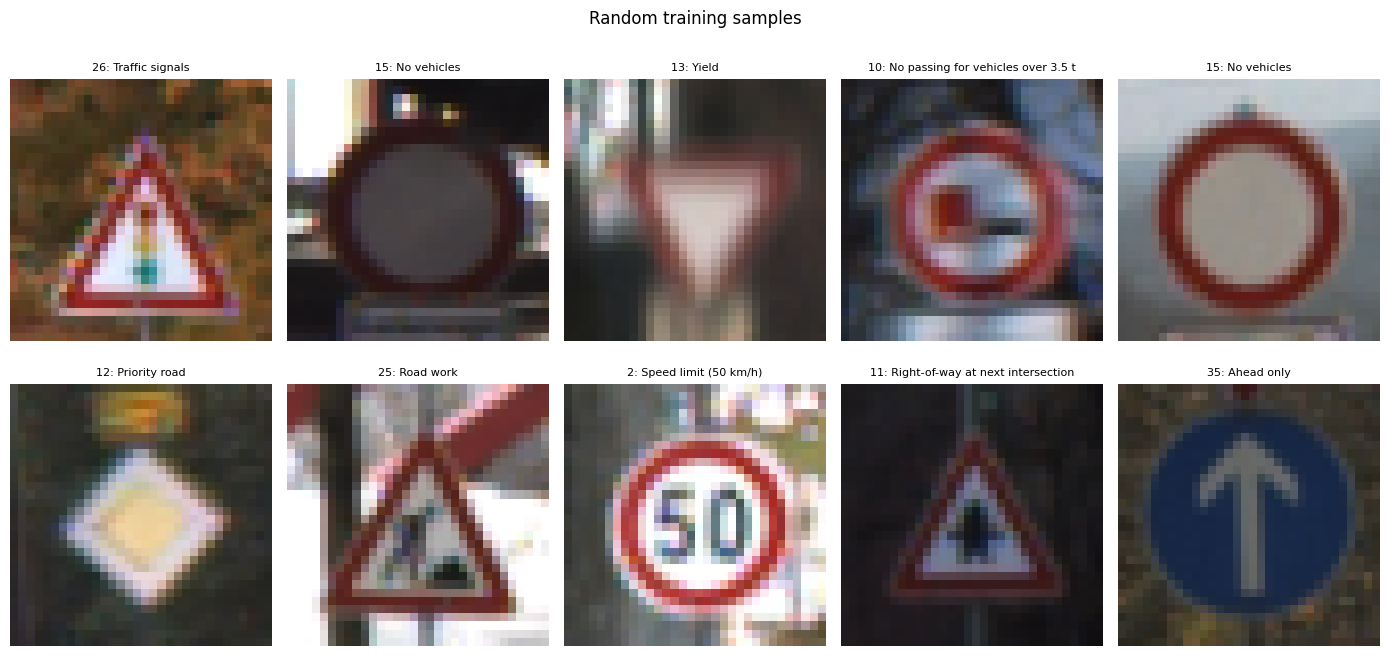

In [15]:
from src.data_loader import (set_seeds, load_sign_names, load_train_data,
                             plot_sample_images, plot_class_distribution)
from src.preprocess import normalize_images, plot_augmented_examples

set_seeds()
config.RESULTS_DIR.mkdir(exist_ok=True)
sign_names = load_sign_names()
X, y = load_train_data()
print('Training images:', X.shape, '| labels:', y.shape)
plot_sample_images(X, y, sign_names, save_path=config.RESULTS_DIR / 'sample_images.png');

The classes are **imbalanced**: some have about 200 images, others over 2,000.

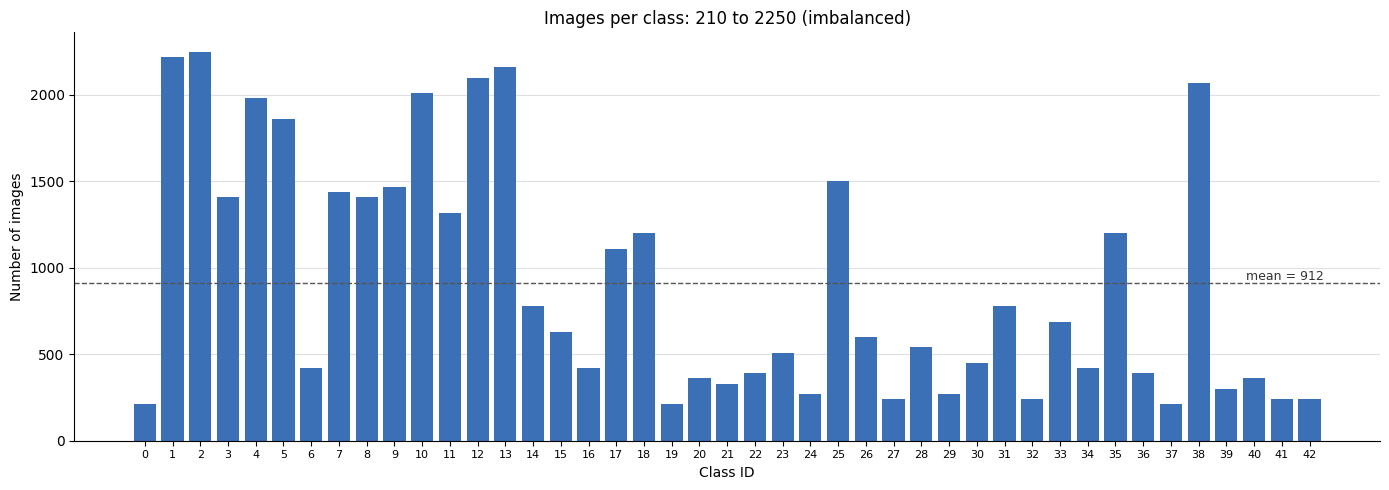

In [16]:
plot_class_distribution(y, save_path=config.RESULTS_DIR / 'class_distribution.png');

### 3.3 Data augmentation

Random rotation (10 degrees), zoom (0.15), shift (0.1) and shear (0.1).
**No flips**: flipping would turn "turn left" into "turn right".

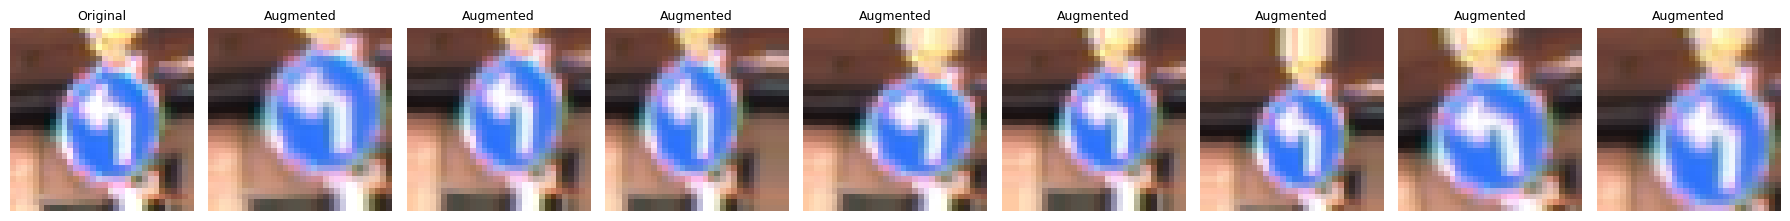

In [17]:
turn_left = normalize_images(X[y == 34][:1])[0]   # class 34 = Turn left ahead
plot_augmented_examples(turn_left, save_path=config.RESULTS_DIR / 'augmentation_examples.png');
del X, y   # free memory before training

## 4. Model A: custom CNN

Two blocks of `Conv(3x3) -> Conv(3x3) -> MaxPool -> Dropout(0.25)` (32 then 64 filters),
then `Flatten -> Dense(256) -> Dropout(0.5) -> Dense(43, softmax)`, with
BatchNormalization after each convolution. Adam (lr 0.001), batch 64, up to 20 epochs,
EarlyStopping, ModelCheckpoint and ReduceLROnPlateau.

Set `TRAIN_BASELINE = True` to also train the plain CNN without BatchNorm (~10 more minutes).

In [18]:
from src.train import train_custom_cnn

TRAIN_BASELINE = False
if TRAIN_BASELINE:
    train_custom_cnn(use_batchnorm=False)
train_custom_cnn(use_batchnorm=True);

Loading train data from cache: cache_train_32.npz
Reading test images from disk (first time only)...


Model: "custom_cnn_bn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 10, 10, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       409,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 487,243 (1.86 MB)

 Trainable params: 486,859 (1.86 MB)

 Non-trainable params: 384 (1.50 KB)

Epoch 1/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.2857 - loss: 2.8030
Epoch 1: val_accuracy improved from None to 0.63134, saving model to /content/signsense/models/custom_cnn_bn.keras

Epoch 1: finished saving model to /content/signsense/models/custom_cnn_bn.keras
491/491 ━━━━━━━━━━━━━━━━━━━━ 44s 64ms/step - accuracy: 0.4374 - loss: 1.9818 - val_accuracy: 0.6313 - val_loss: 1.1516 - learning_rate: 0.0010
Epoch 2/20
490/491 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.7164 - loss: 0.8617
Epoch 2: val_accuracy improved from 0.63134 to 0.97335, saving model to /content/signsense/models/custom_cnn_bn.keras

Epoch 2: finished saving model to /content/signsense/models/custom_cnn_bn.keras
491/491 ━━━━━━━━━━━━━━━━━━━━ 20s 41ms/step - accuracy: 0.7622 - loss: 0.7267 - val_accuracy: 0.9733 - val_loss: 0.0934 - learning_rate: 0.0010
Epoch 3/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8629 - loss: 0.4275
Epoch 3: val_accuracy improved from 0.97335 to 0.98750, sa

### 4.1 Evaluate Model A on the official test set

Loading test data from cache: cache_test_32.npz

custom_cnn_bn: test accuracy = 98.24% (222 wrong out of 12630)

5 worst classes (lowest F1):
 ClassId                    SignName  precision  recall     f1                   predicted_as                             mistaken_for_it
      40        Roundabout mandatory     0.7264  0.8556 0.7857 7: Speed limit (100 km/h) (9x)                     12: Priority road (22x)
      21                Double curve     1.0000  0.6667 0.8000 1: Speed limit (30 km/h) (14x)                                           -
      22                  Bumpy road     0.9896  0.7917 0.8796            25: Road work (25x)                      12: Priority road (1x)
      30          Beware of ice/snow     0.8834  0.9600 0.9201     28: Children crossing (2x) 11: Right-of-way at next intersection (19x)
      19 Dangerous curve to the left     0.8696  1.0000 0.9302                              -                       21: Double curve (9x)

Plots and tables saved to /co

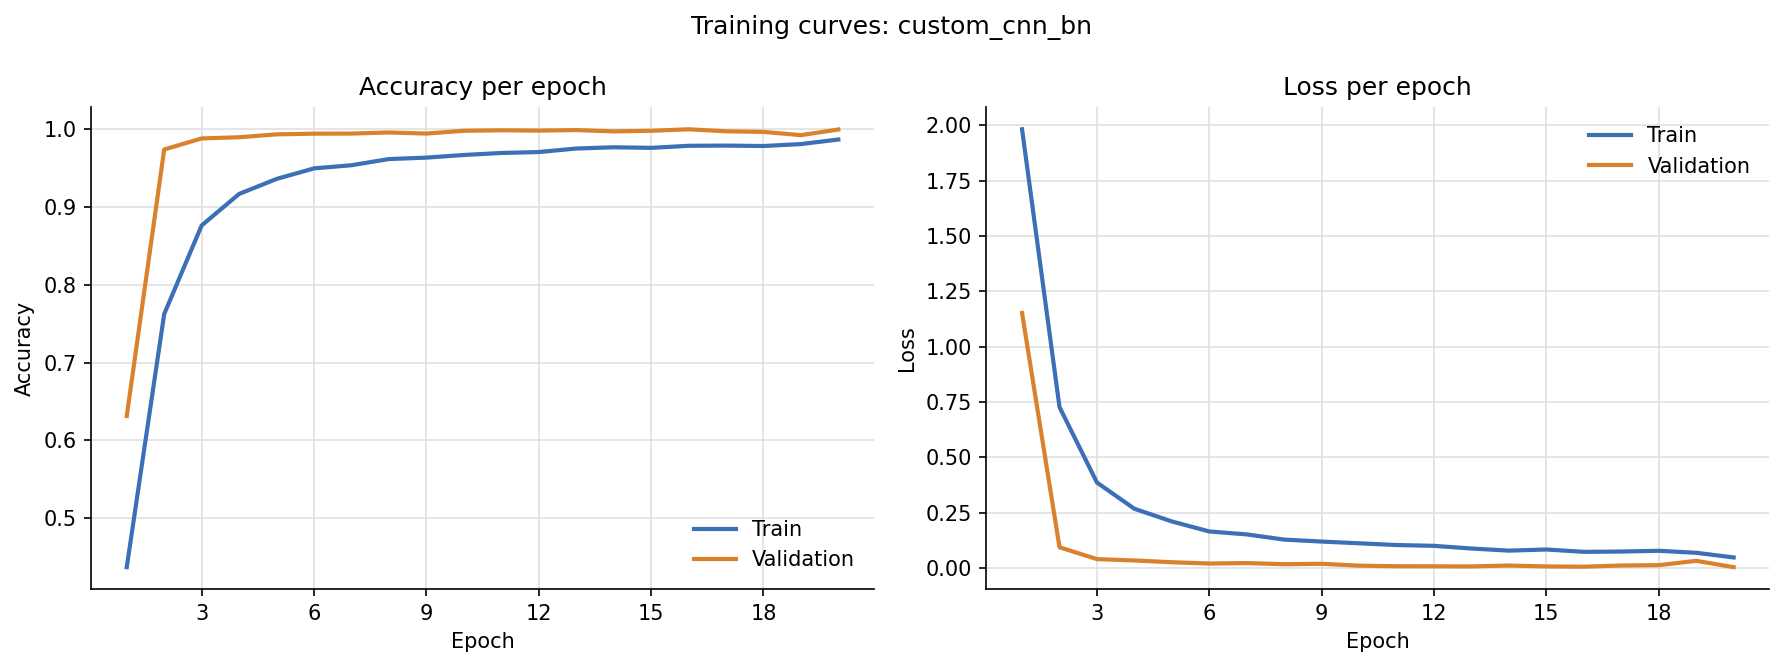

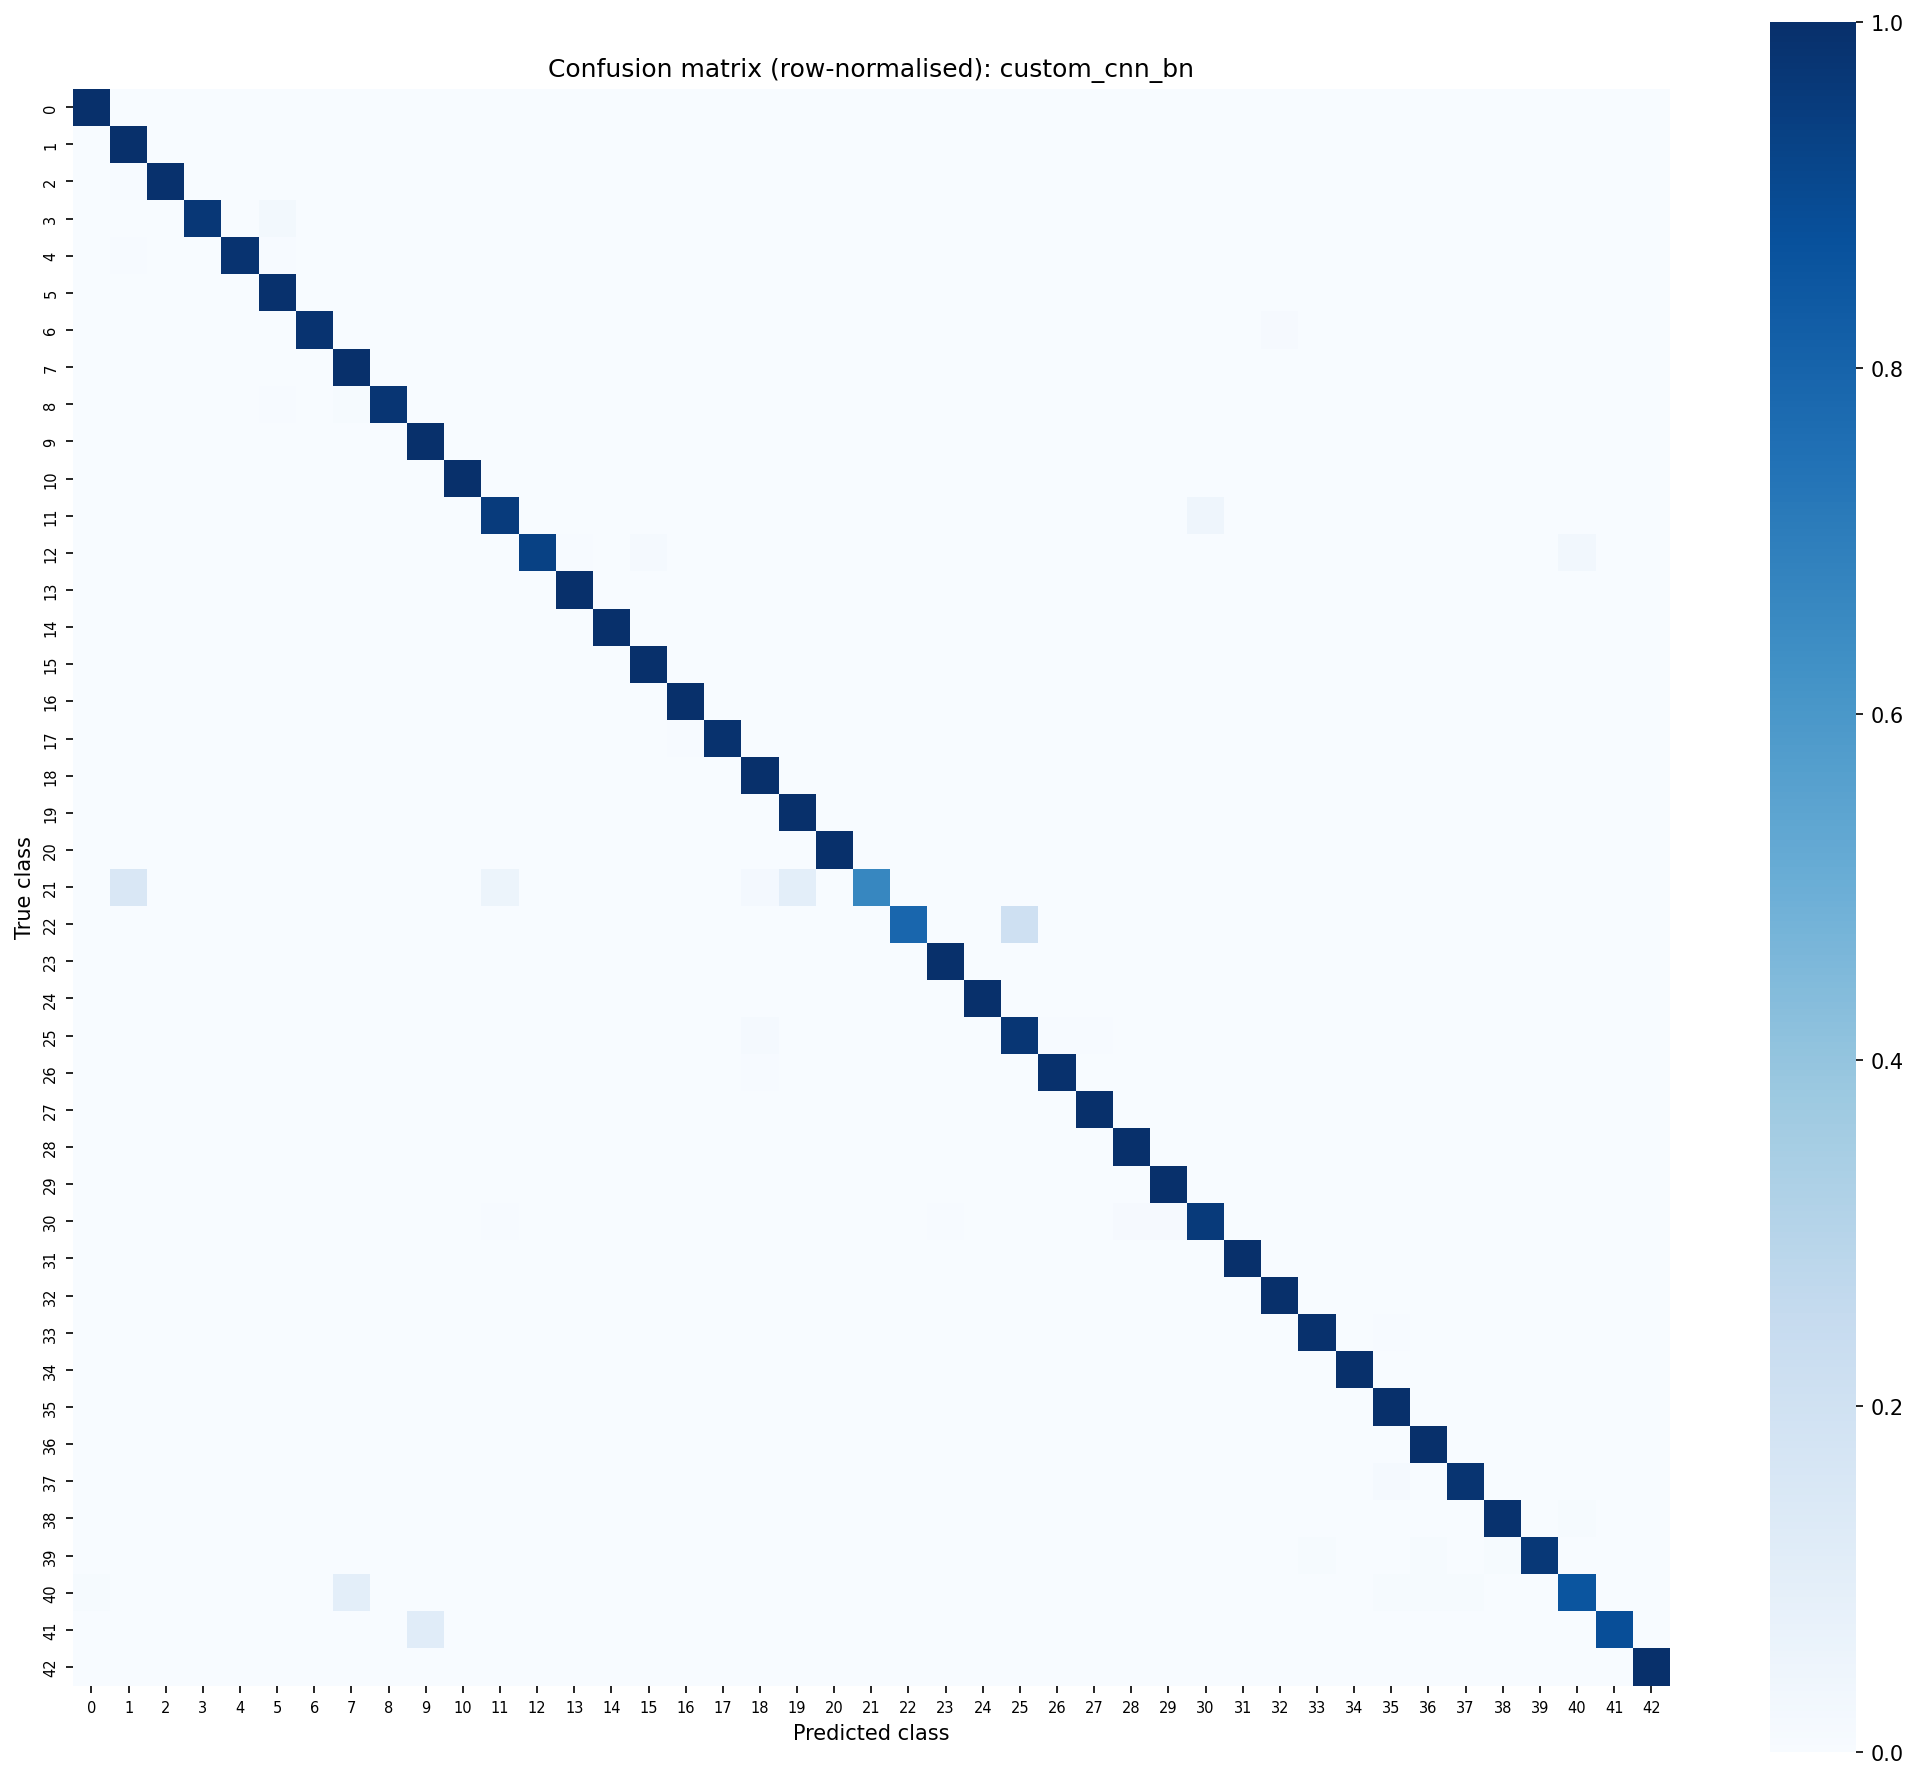

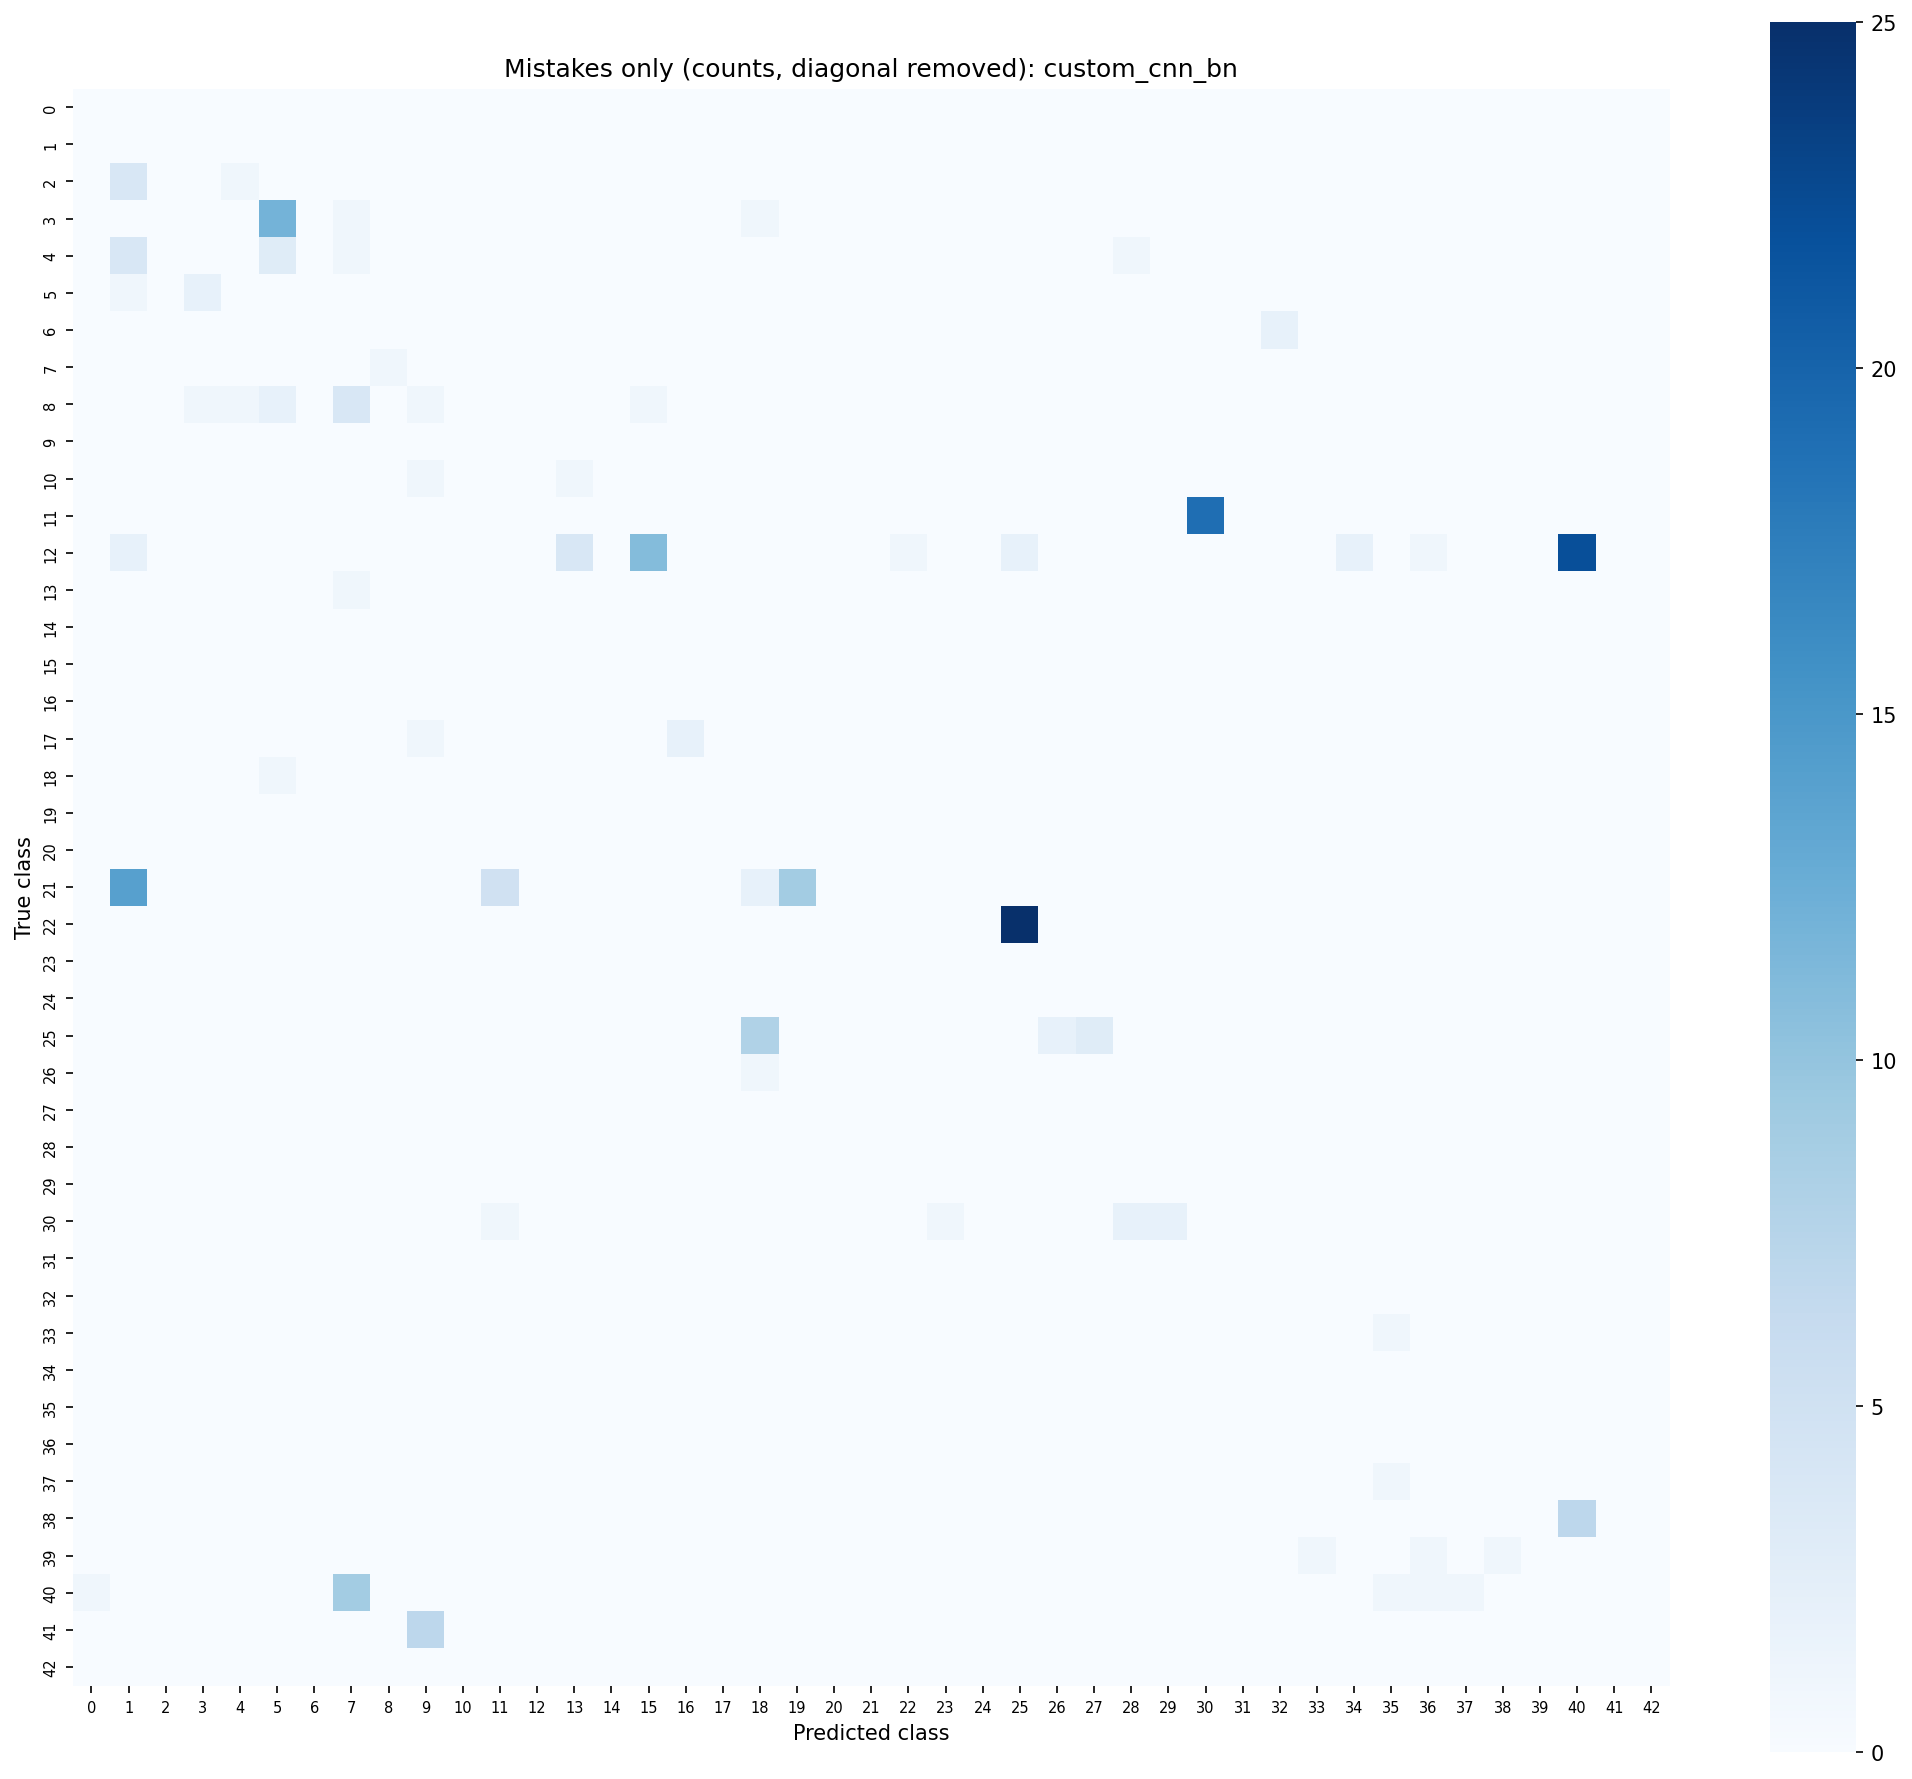

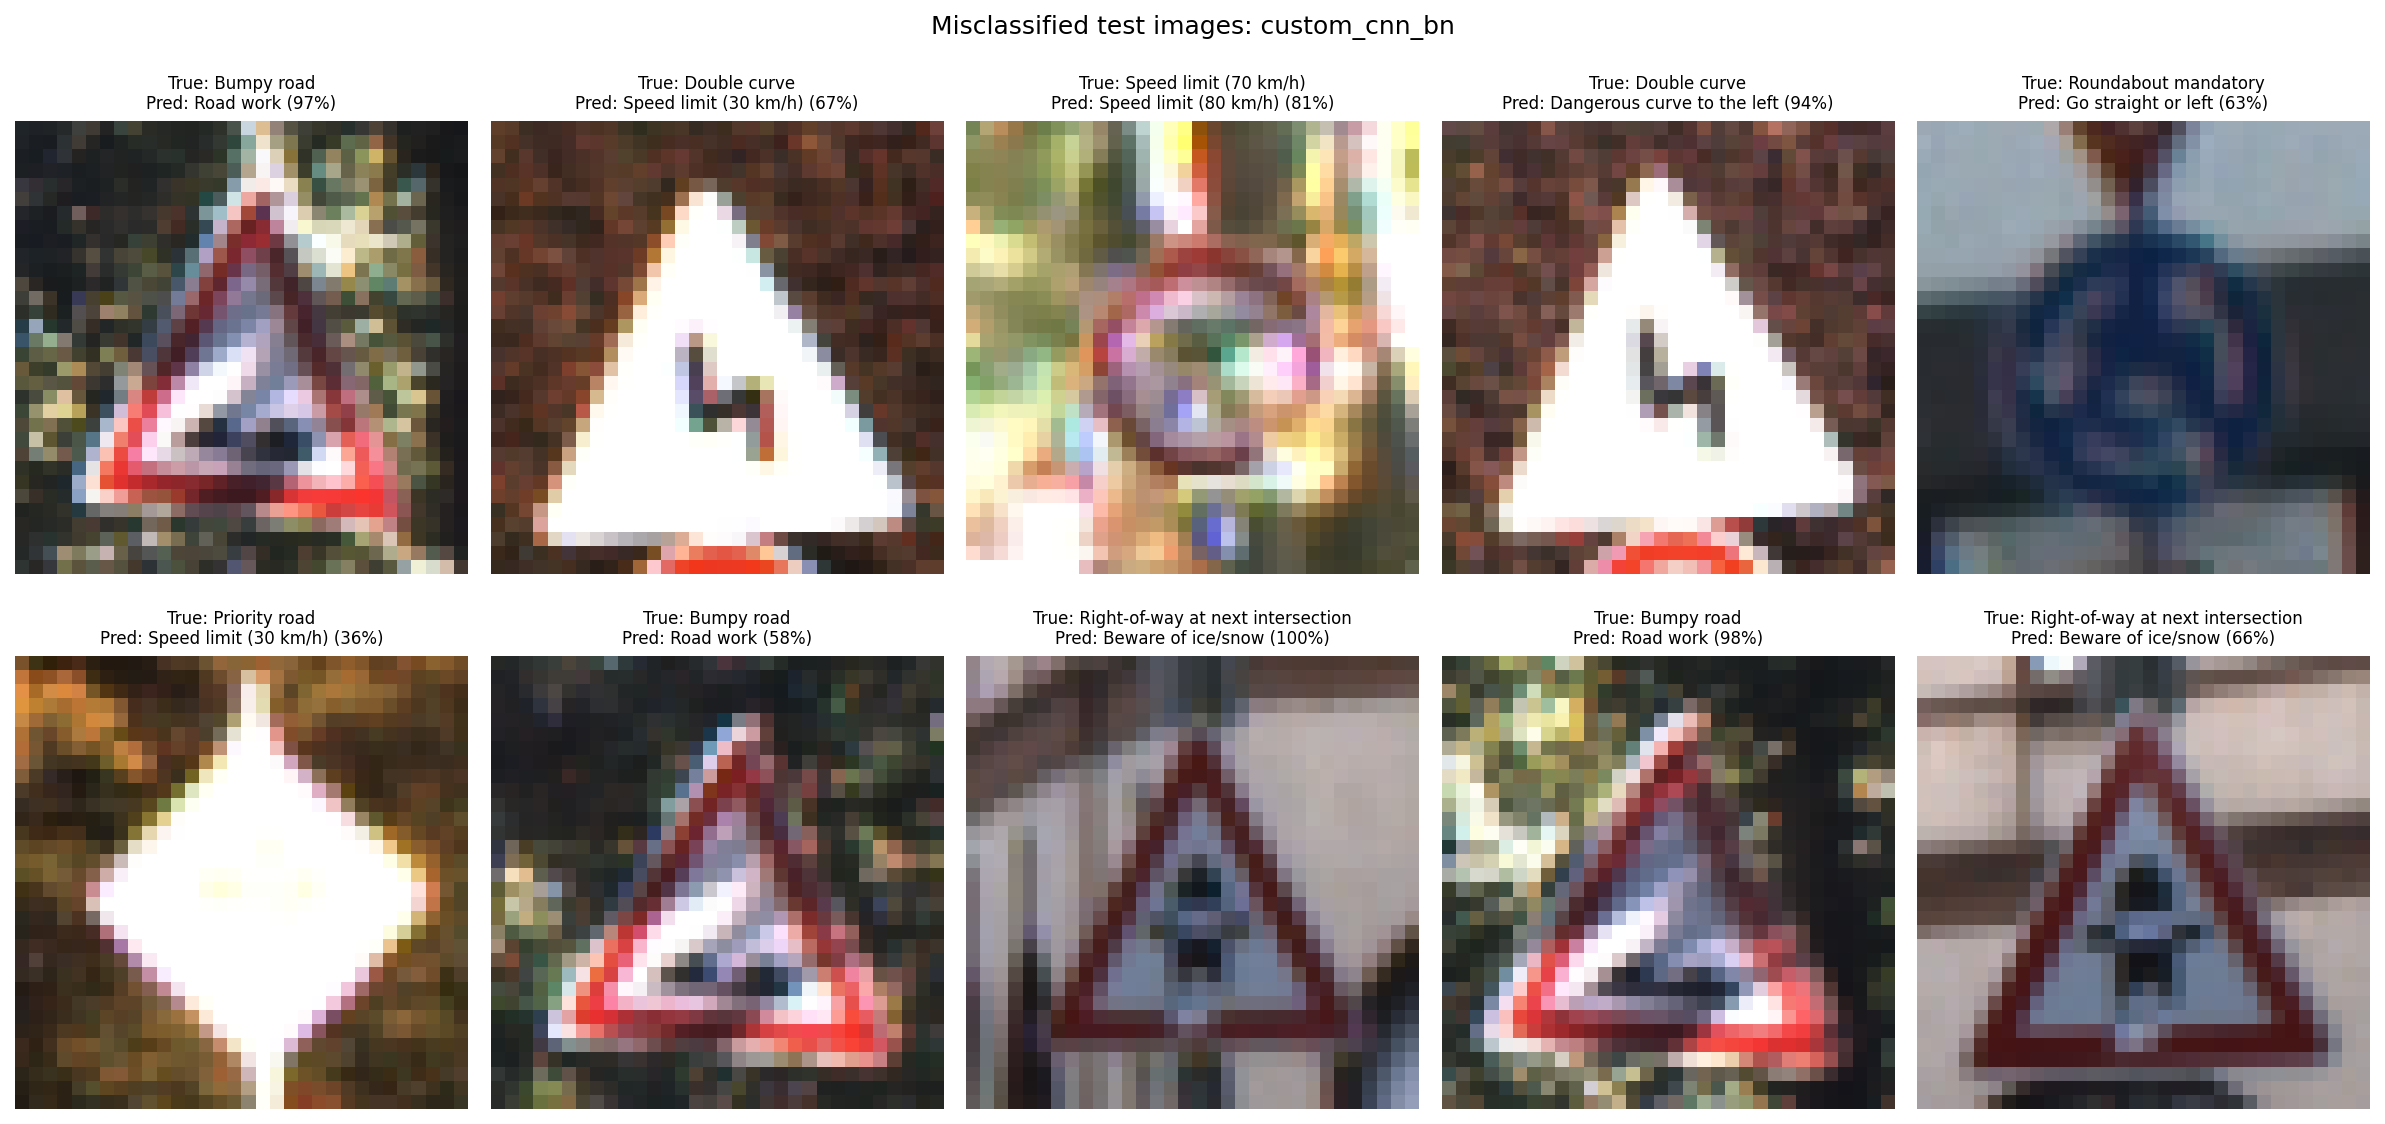

In [19]:
from src.evaluate import evaluate_model
from IPython.display import Image, display
import pandas as pd

evaluate_model('custom_cnn_bn')
for plot in ['curves', 'confusion_matrix', 'confusion_errors', 'misclassified']:
    display(Image(f'results/{plot}_custom_cnn_bn.png'))

## 5. Model B: MobileNetV2 transfer learning

ImageNet-pretrained MobileNetV2 at 96x96 with a new head
(`GlobalAveragePooling -> Dropout(0.3) -> Dense(43)`).
Stage 1 trains the head with the base frozen; stage 2 fine-tunes the top 60 layers
with a learning rate of 1e-4. Data flows through a `tf.data` pipeline to save memory.

In [20]:
from src.train import train_mobilenet
train_mobilenet();

Reading train images from disk (first time only)...
  class 42: done
Reading test images from disk (first time only)...
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 43)             │        55,083 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,313,067 (8.82 MB)

 Trainable params: 55,083 (215.17 KB)

 Non-trainable params: 2,257,984 (8.61 MB)


=== Stage 1: training the new classifier head (MobileNetV2 base frozen) ===
Epoch 1/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.4399 - loss: 2.0092
Epoch 1: val_accuracy improved from None to 0.68783, saving model to /content/signsense/models/mobilenetv2.keras

Epoch 1: finished saving model to /content/signsense/models/mobilenetv2.keras
491/491 ━━━━━━━━━━━━━━━━━━━━ 43s 64ms/step - accuracy: 0.5805 - loss: 1.3828 - val_accuracy: 0.6878 - val_loss: 0.9657 - learning_rate: 0.0010
Epoch 2/10
489/491 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7400 - loss: 0.7926
Epoch 2: val_accuracy improved from 0.68783 to 0.72558, saving model to /content/signsense/models/mobilenetv2.keras

Epoch 2: finished saving model to /content/signsense/models/mobilenetv2.keras
491/491 ━━━━━━━━━━━━━━━━━━━━ 19s 38ms/step - accuracy: 0.7518 - loss: 0.7558 - val_accuracy: 0.7256 - val_loss: 0.8265 - learning_rate: 0.0010
Epoch 3/10
490/491 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.7809 - lo

### 5.1 Evaluate Model B on the official test set

Loading test data from cache: cache_test_96.npz

mobilenetv2: test accuracy = 88.83% (1411 wrong out of 12630)

5 worst classes (lowest F1):
 ClassId                     SignName  precision  recall     f1                          predicted_as               mistaken_for_it
      37          Go straight or left     0.7917  0.3167 0.4524        36: Go straight or right (21x) 36: Go straight or right (4x)
      27                  Pedestrians     0.5179  0.4833 0.5000           28: Children crossing (28x)   28: Children crossing (13x)
      20 Dangerous curve to the right     0.6512  0.6222 0.6364 19: Dangerous curve to the left (18x)   30: Beware of ice/snow (7x)
      21                 Double curve     0.6058  0.7000 0.6495 19: Dangerous curve to the left (10x)     26: Traffic signals (11x)
       0        Speed limit (20 km/h)     0.8049  0.5500 0.6535        4: Speed limit (70 km/h) (11x) 1: Speed limit (30 km/h) (3x)

Plots and tables saved to /content/signsense/results


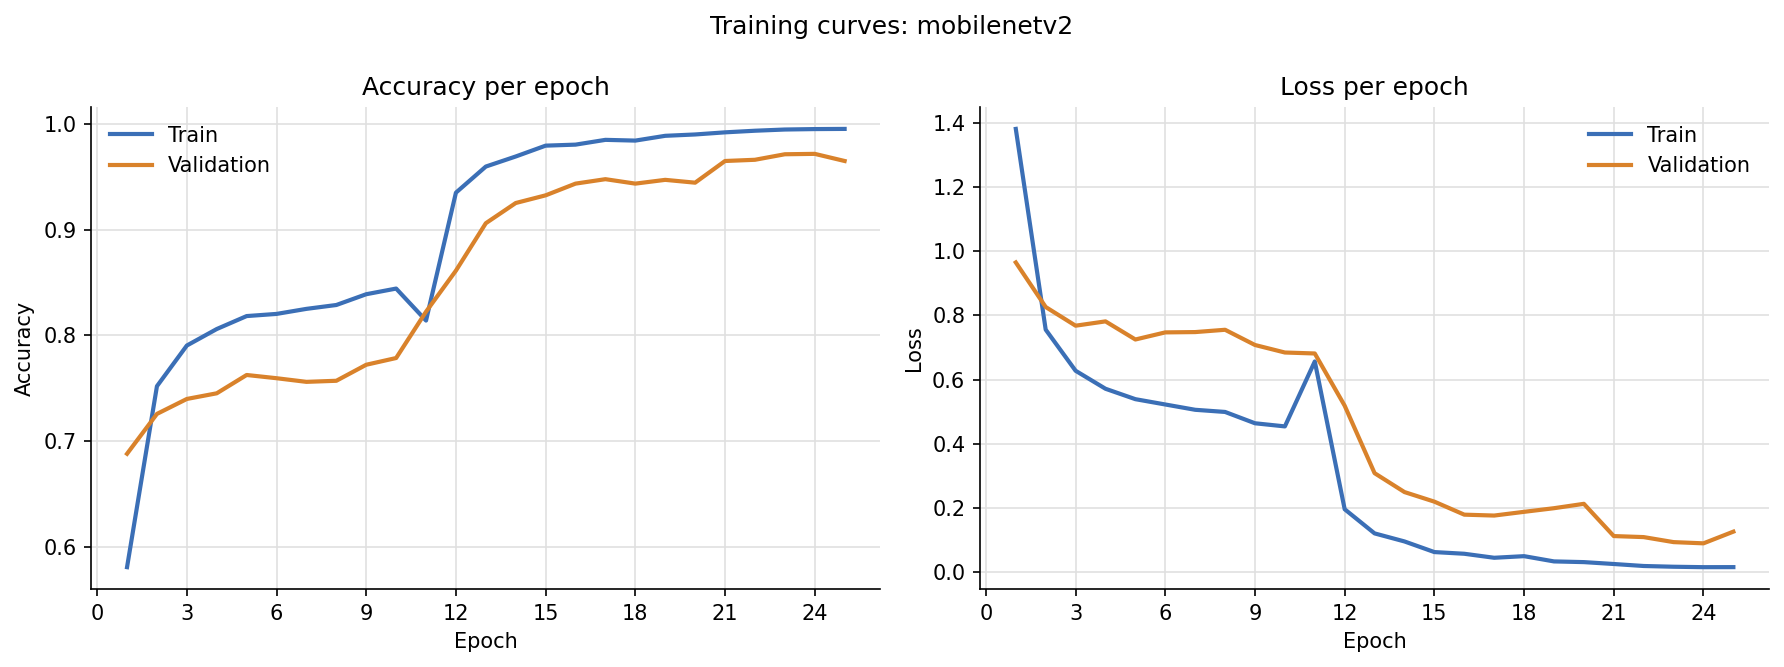

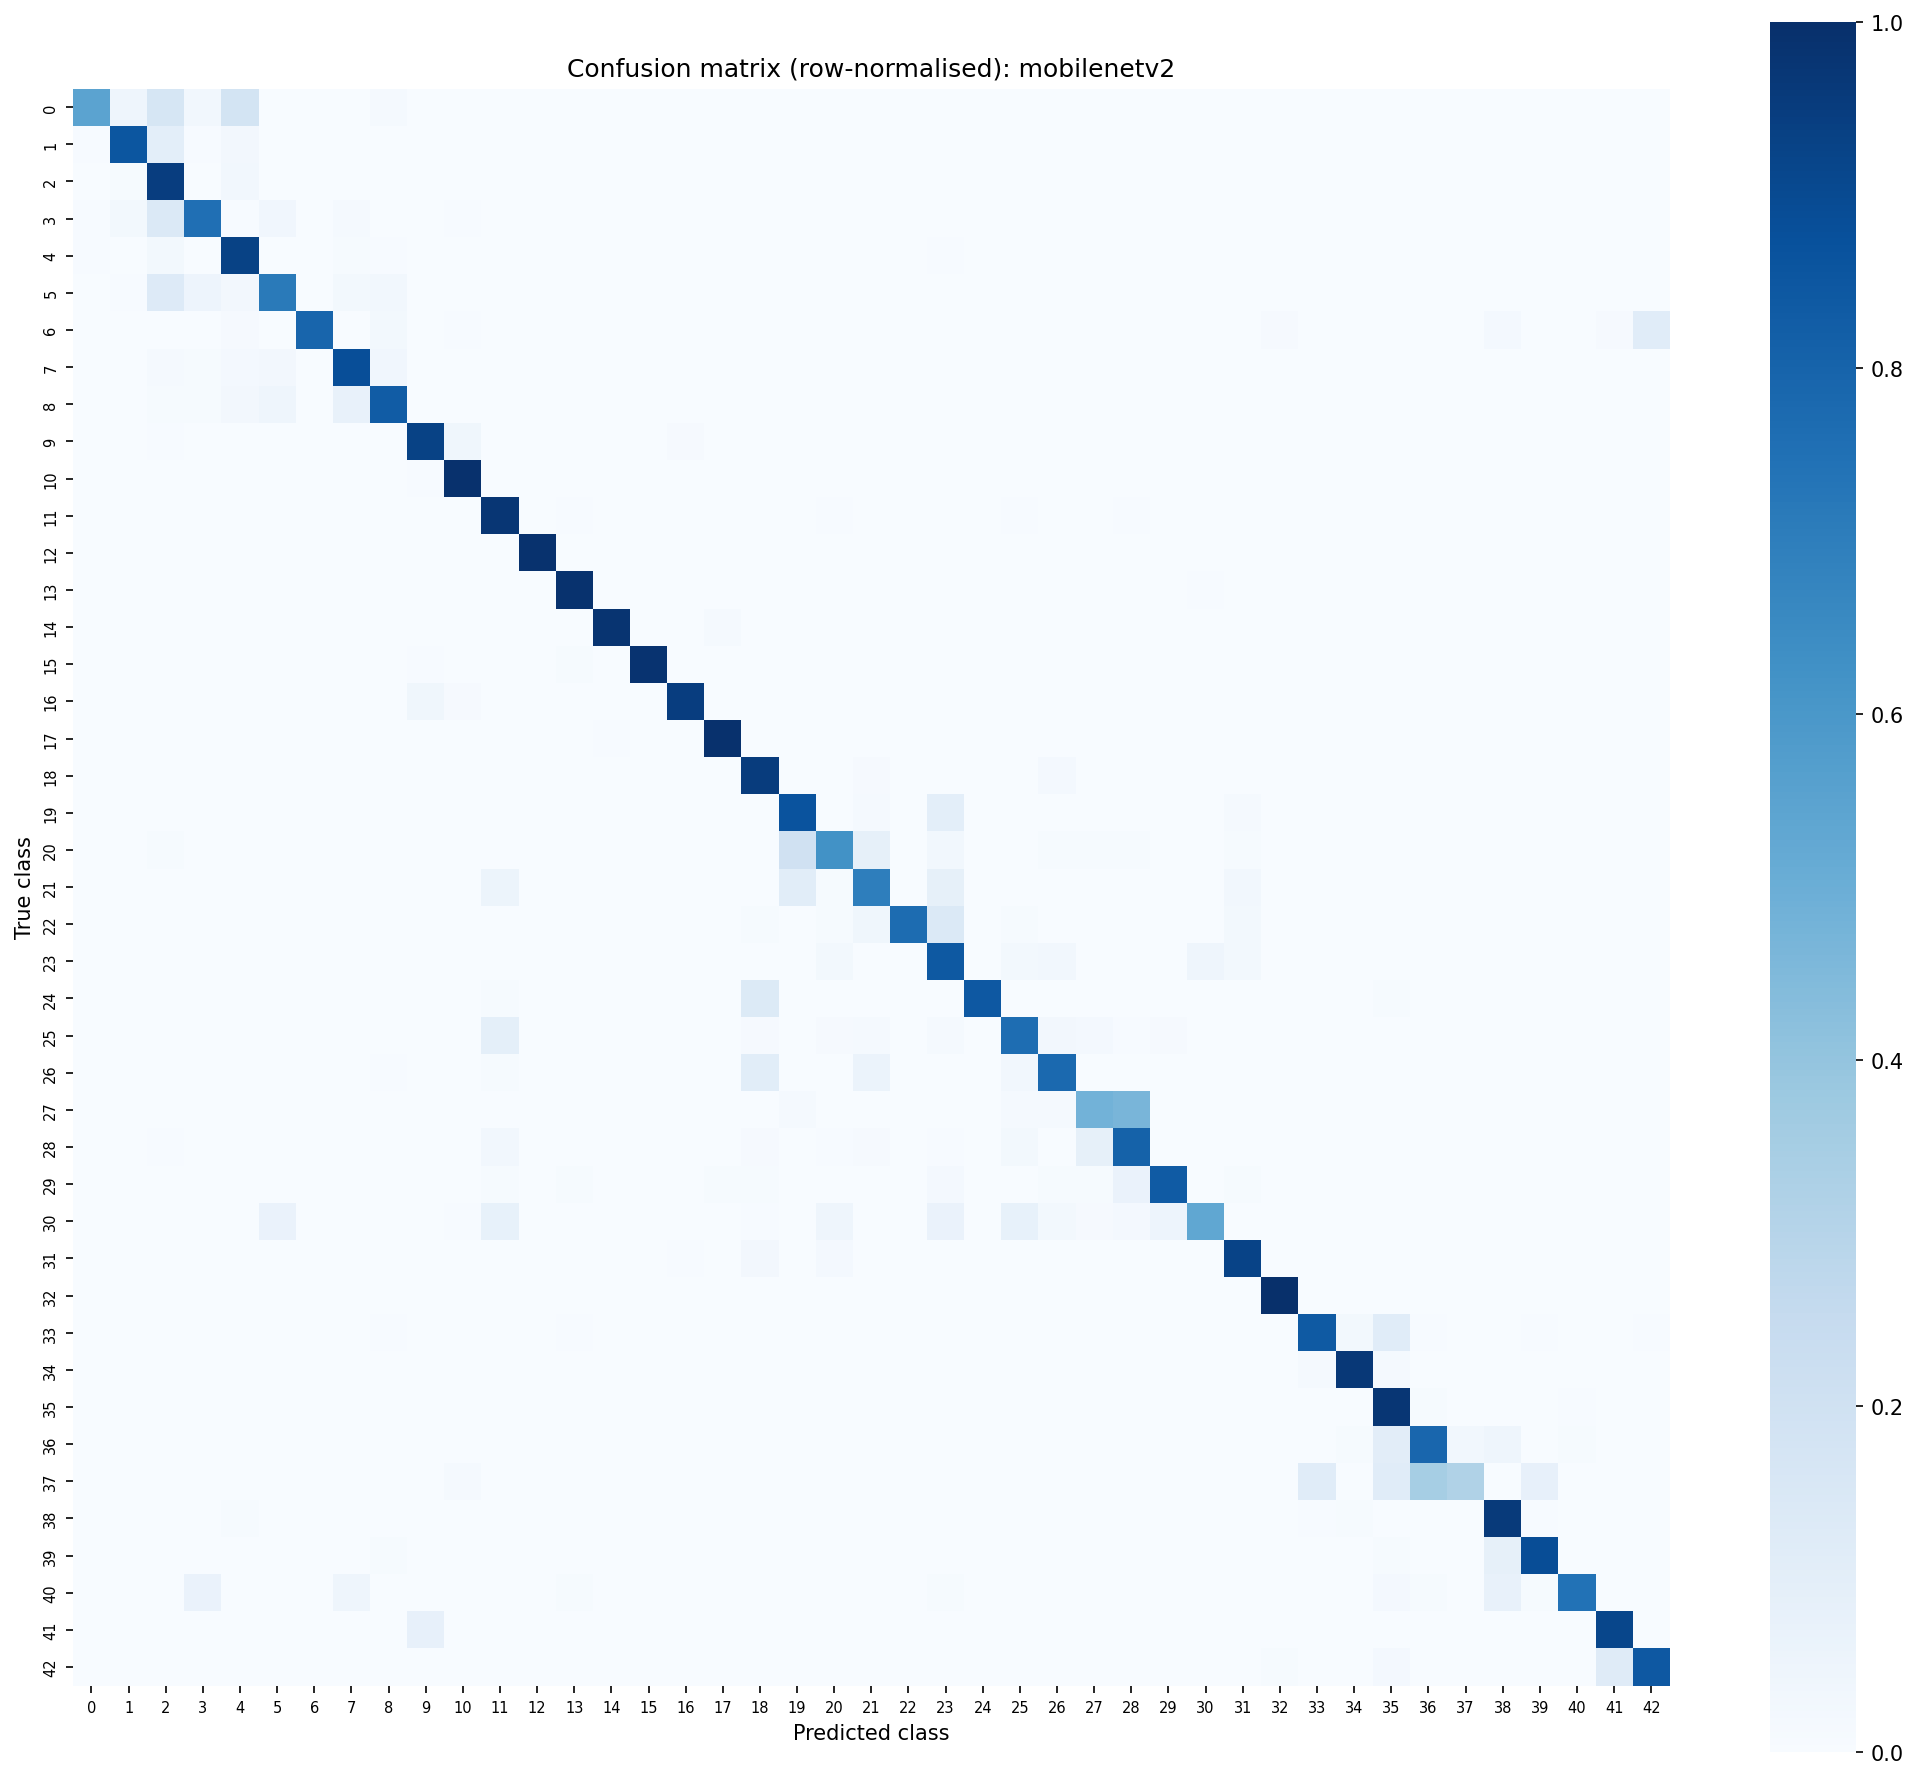

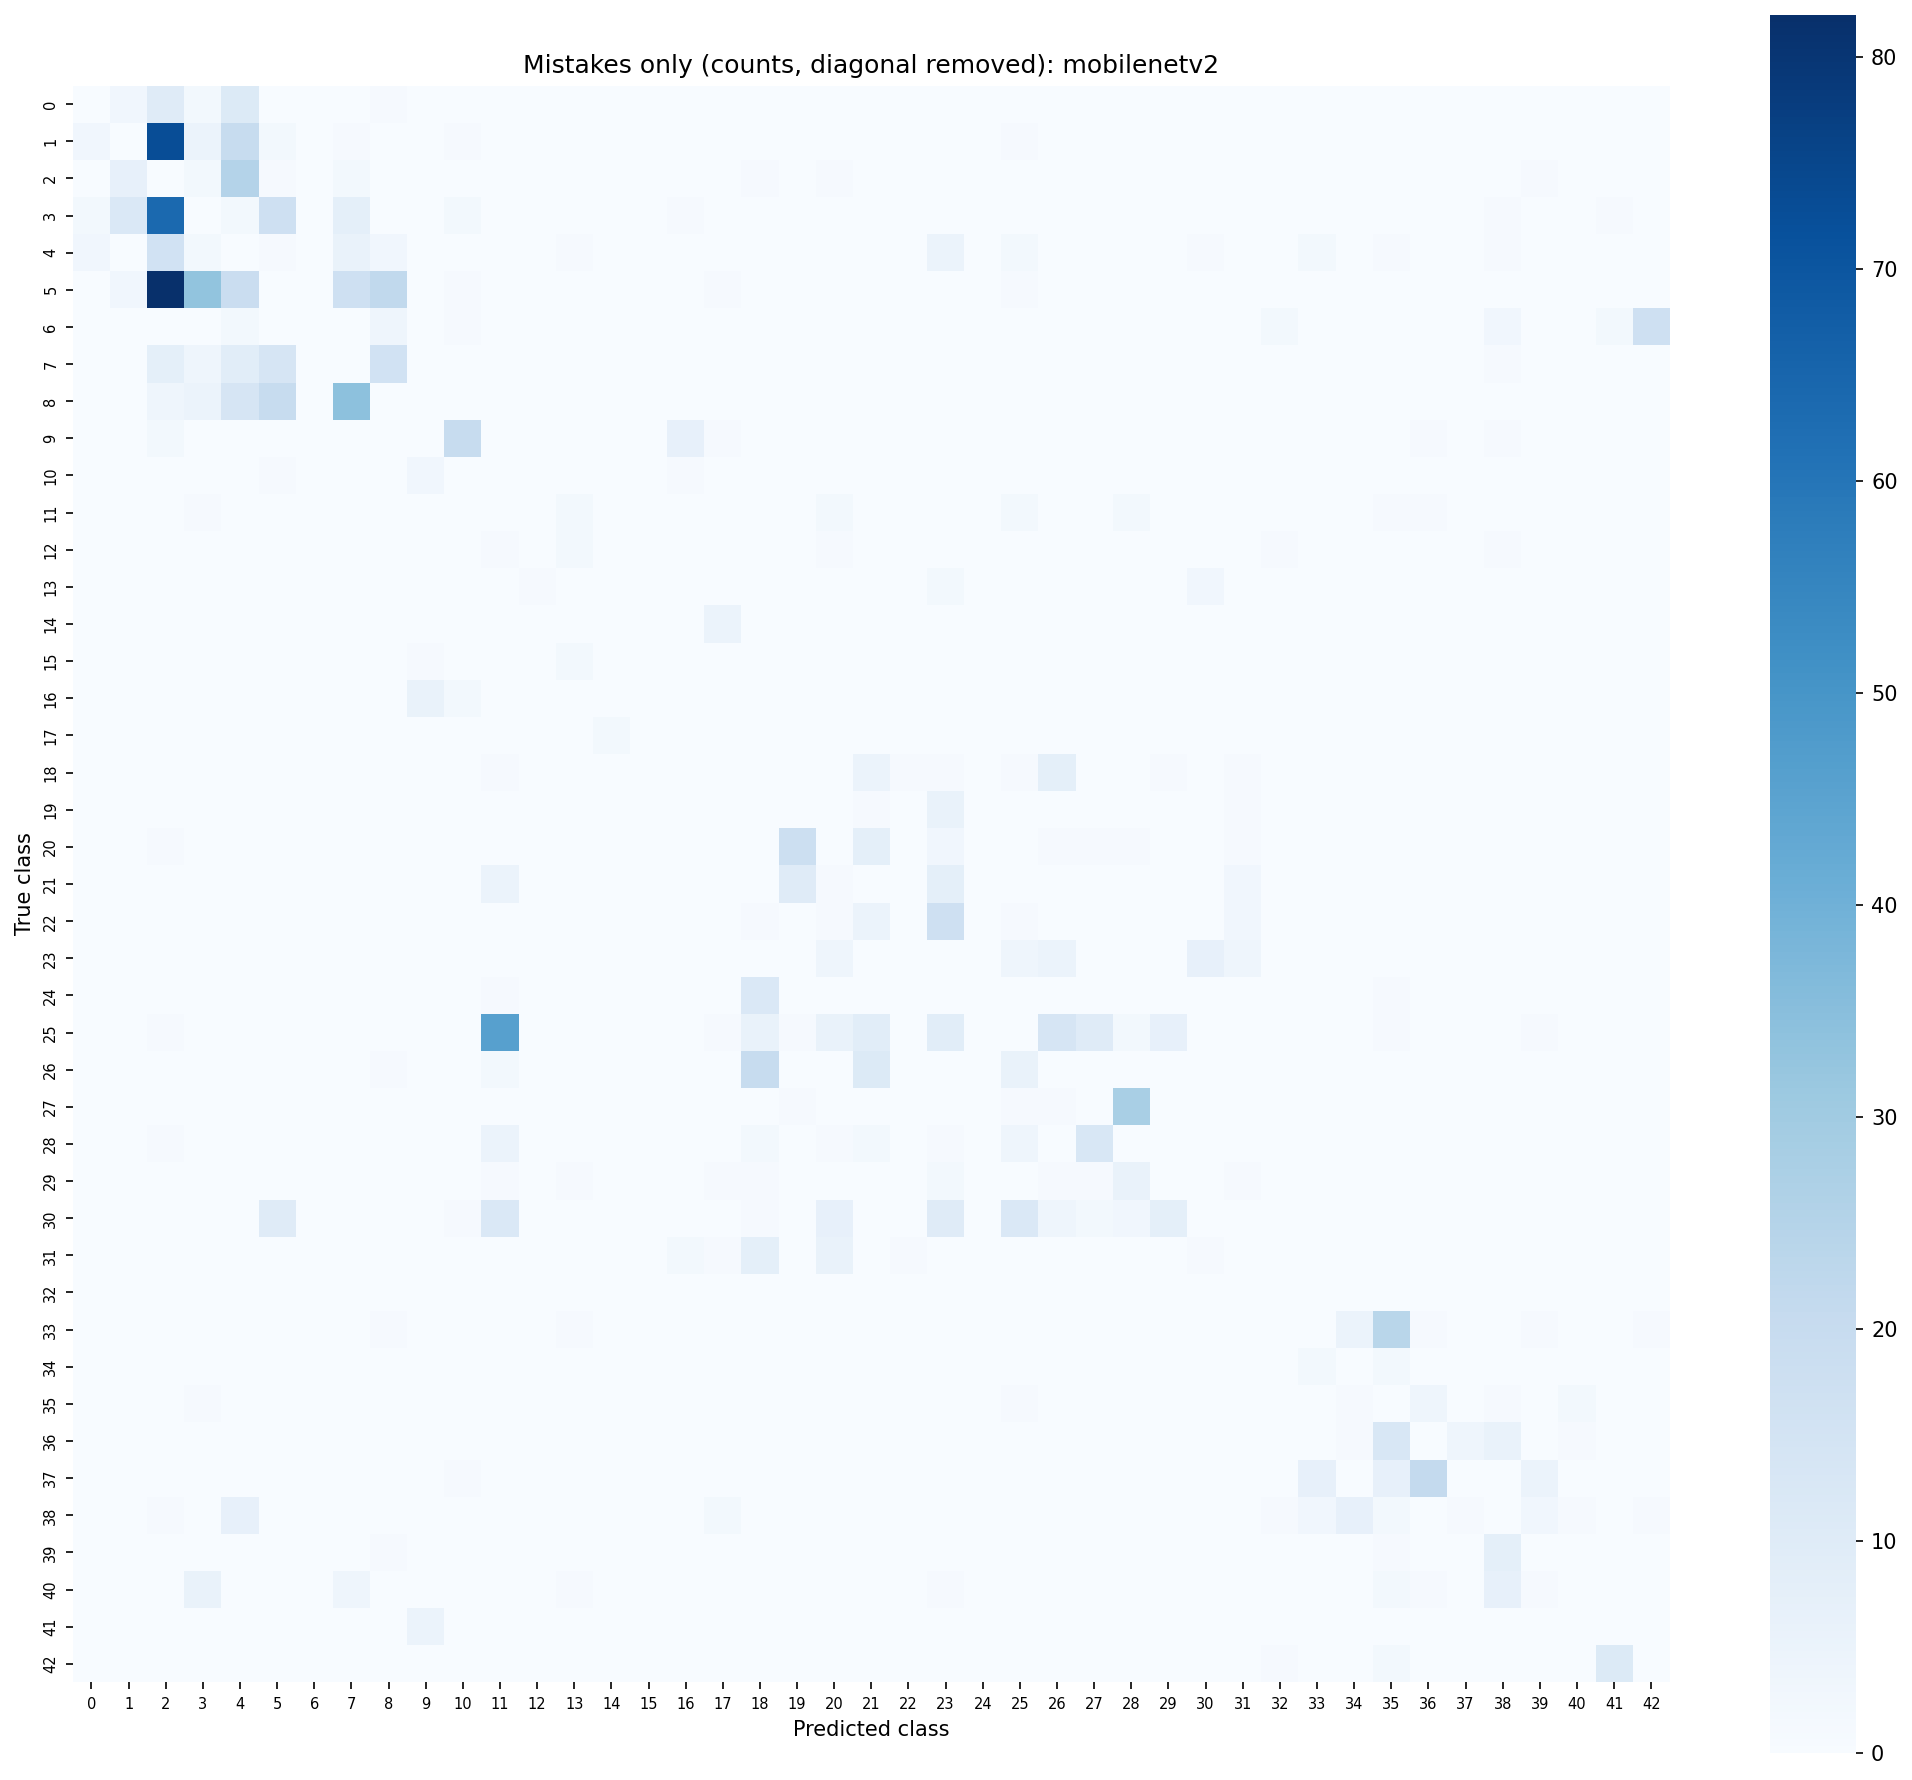

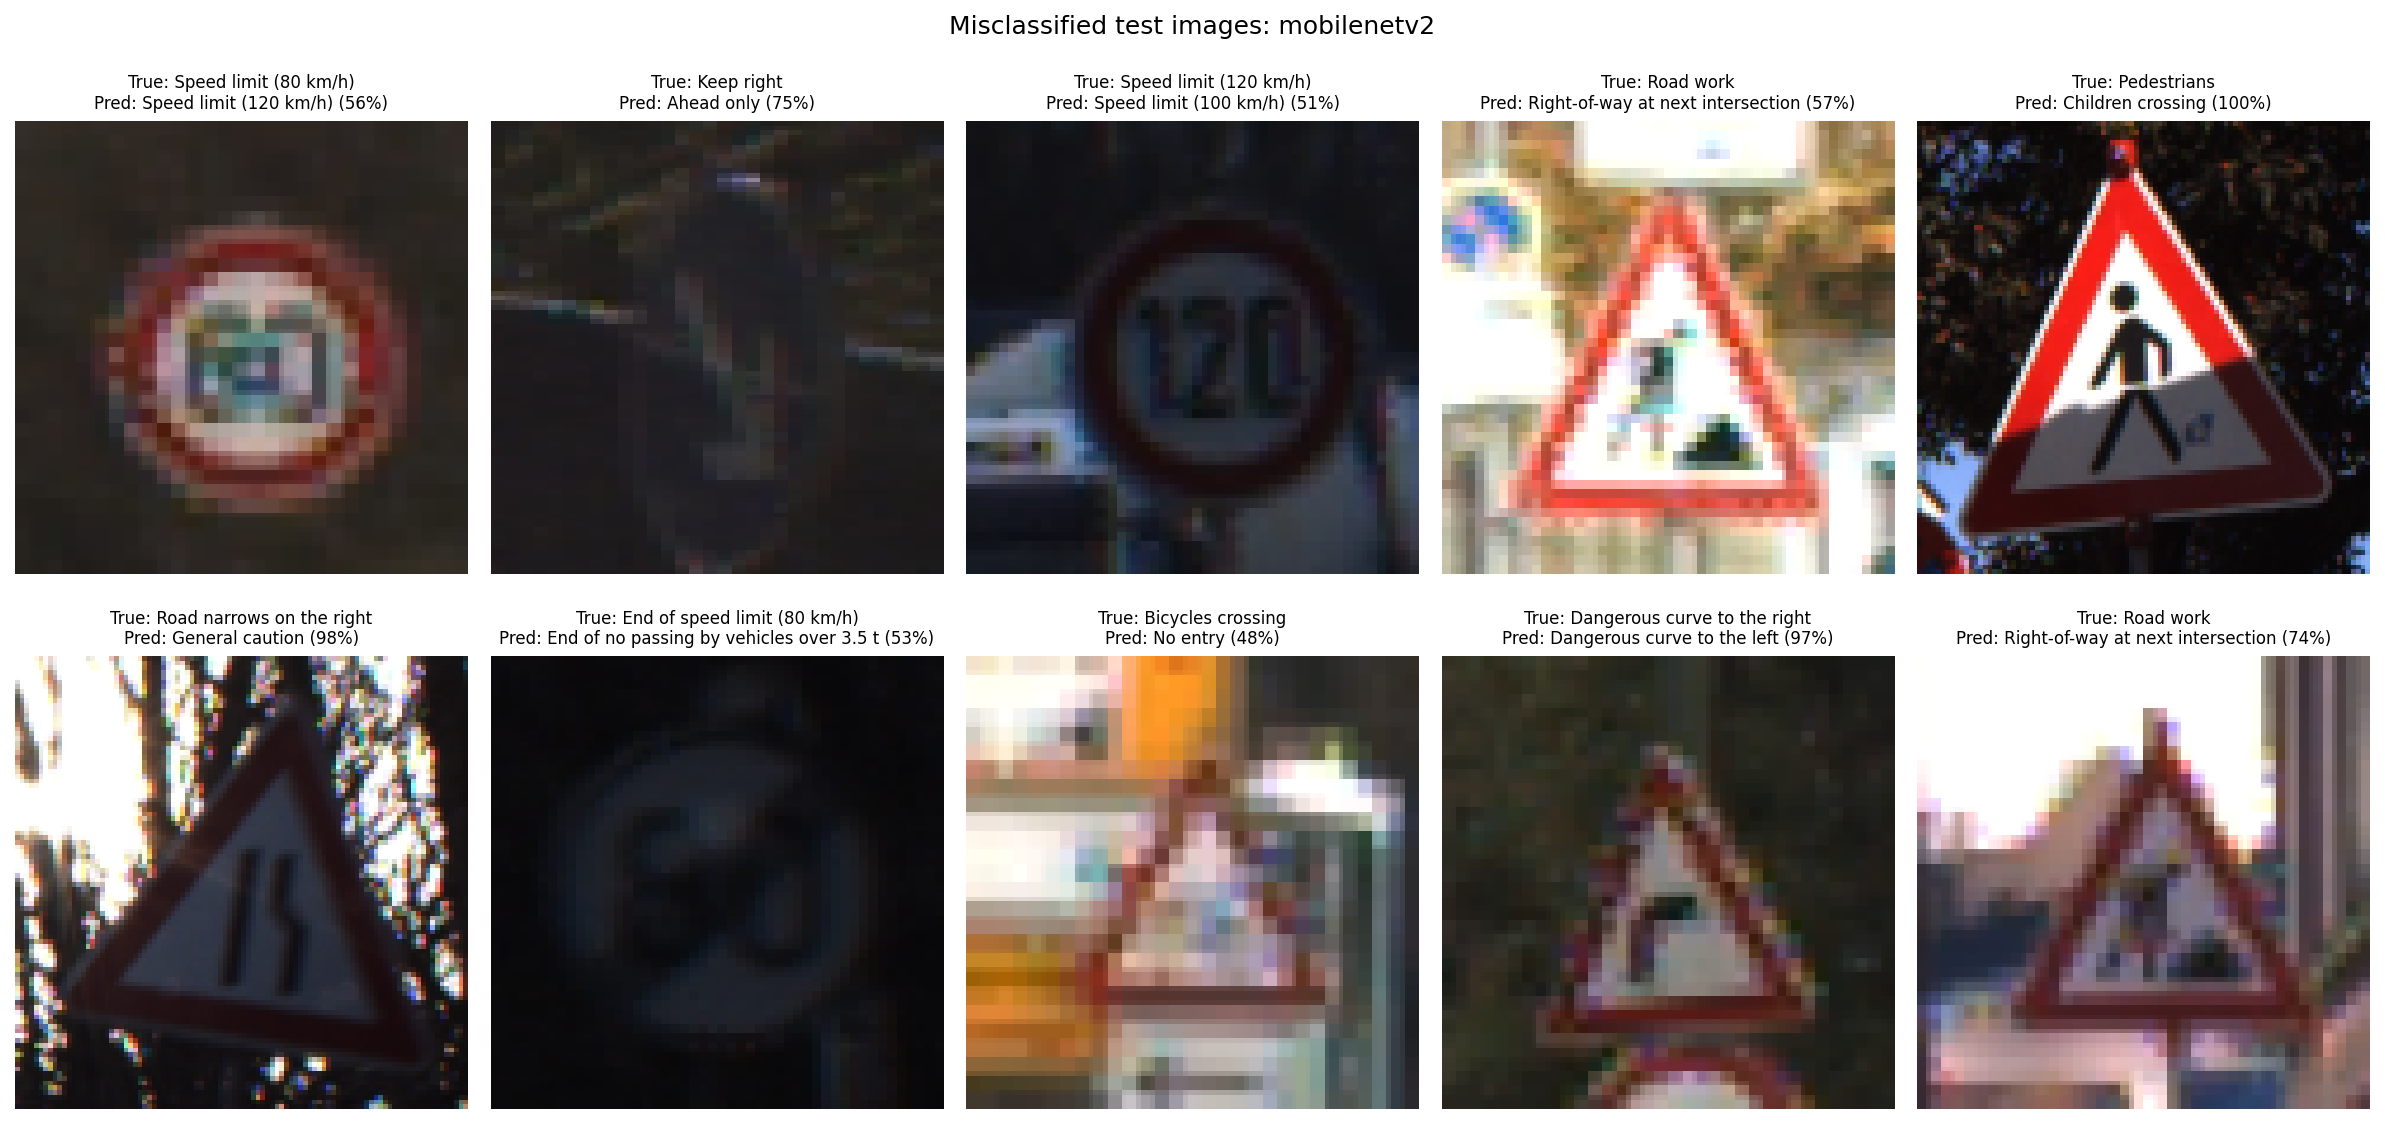

In [21]:
from src.evaluate import evaluate_model
from IPython.display import Image, display
import pandas as pd

evaluate_model('mobilenetv2')
for plot in ['curves', 'confusion_matrix', 'confusion_errors', 'misclassified']:
    display(Image(f'results/{plot}_mobilenetv2.png'))

## 6. Comparison

Skipping custom_cnn: not trained or not evaluated yet
                                Model Input size  Params  Train time (min)     Hardware  Best val accuracy (%)  Test accuracy (%)  Model file (MB)
     Custom CNN + BatchNorm (Model A)      32x32  487243               7.1          GPU                  99.92              98.24              5.9
MobileNetV2 light fine-tuning (run 1)      96x96 2313067               5.6 Colab T4 GPU                  77.93              66.75              NaN
     MobileNetV2 fine-tuned (Model B)      96x96 2313067               9.2          GPU                  97.18              88.83             26.0

Saved comparison.csv and comparison_chart.png to /content/signsense/results


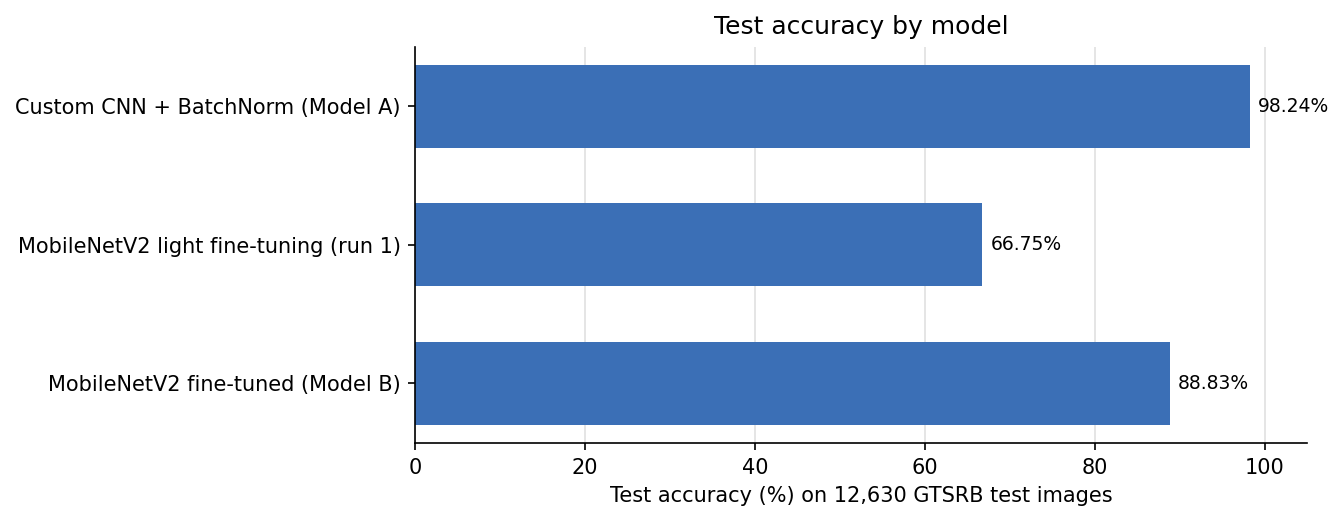

In [22]:
from src.compare import main as compare_models
compare_models()
display(Image('results/comparison_chart.png'))

**Our results** (official test set, 12,630 images):

| Model | Params | Test accuracy |
|---|---|---|
| Custom CNN (baseline) | 486K | 98.05% |
| **Custom CNN + BatchNorm (Model A)** | 487K | **98.60%** |
| MobileNetV2, light fine-tuning (run 1) | 2.31M | 66.75% |
| MobileNetV2, fine-tuned (Model B) | 2.31M | 88.30% |

The small custom CNN wins: ImageNet features suit large, detailed photos rather than tiny,
blurry signs, and GlobalAveragePooling loses position information (left vs right arrows).
Fine-tuning was essential for MobileNetV2. Exact numbers vary slightly between runs.

## 7. Predict single images

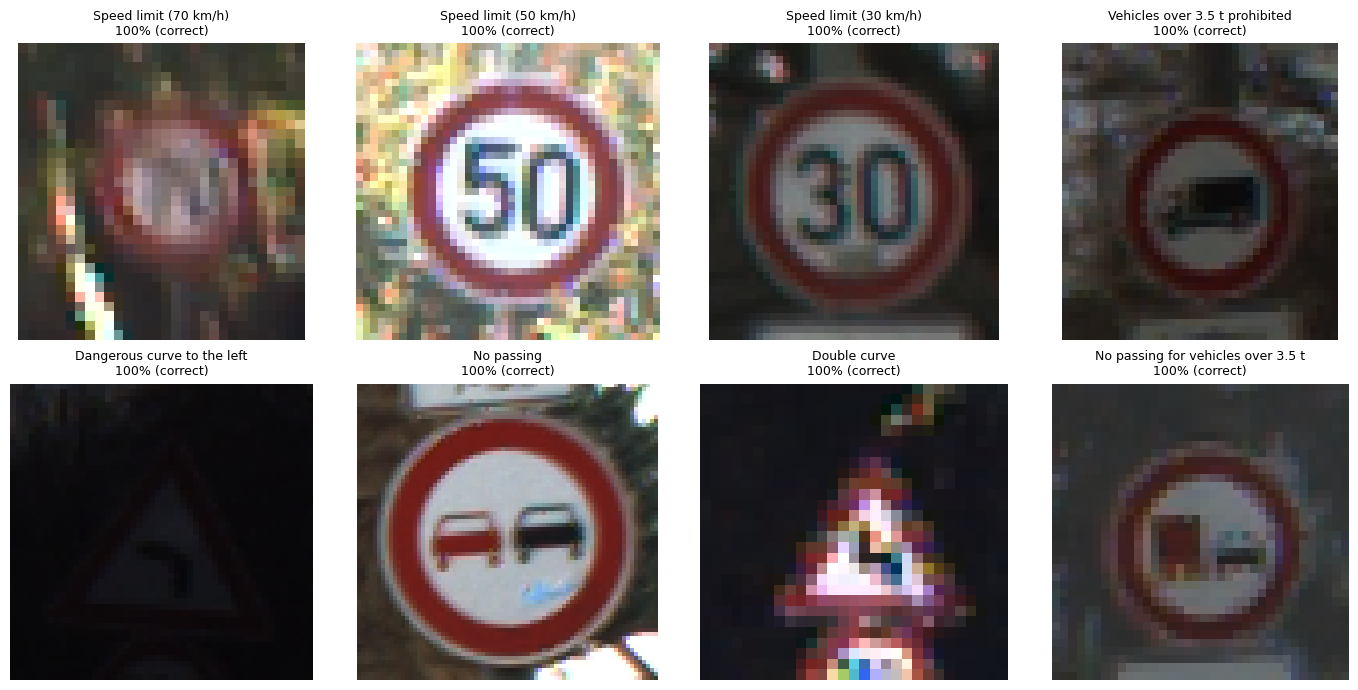

In [23]:
%matplotlib inline
import random
import matplotlib.pyplot as plt
from pathlib import Path
from src.data_loader import find_image_folder
from src.predict import predict_image

test_df = pd.read_csv(config.TEST_CSV)
test_dir = find_image_folder(config.TEST_DIR)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, row in zip(axes.flat, test_df.sample(8, random_state=1).itertuples()):
    image_path = test_dir / Path(row.Path).name
    class_id, name, confidence, top3 = predict_image(image_path)
    ax.imshow(plt.imread(image_path))
    verdict = 'correct' if class_id == row.ClassId else 'WRONG'
    ax.set_title(f'{name}\n{confidence:.0%} ({verdict})', fontsize=9)
    ax.axis('off')
plt.tight_layout()

## 8. Demo app

The Streamlit app (`app/app.py`) runs on a laptop, not in Colab:

```
streamlit run app/app.py
```

Download `models/custom_cnn_bn.keras` and `models/mobilenetv2.keras` from this
runtime into the project's `models/` folder first (or use the models trained locally).